# Frente 1 — Formação: Extensão vs. Poli

**PRO3201 — Estatística e Aplicações · Grupo 10 (J) · Etapa final**

**Objetivo da frente:** avaliar o *valor formativo percebido* das atividades de extensão frente às disciplinas obrigatórias e como o perfil do grupo e a dedicação moldam esse preparo.

**Fio condutor do relatório:** *"Analisar como a participação em grupos de extensão influencia a percepção de preparo profissional e as escolhas de trajetória de carreira dos estudantes da Poli-USP."*

Este notebook segue o encadeamento do guia — **diagnóstico descritivo → testes de hipótese (com tamanho de efeito) → modelos explicativos/preditivos** — e registra cada pergunta no bloco padronizado:
(a) pergunta e hipóteses; (b) teste/modelo e verificação de premissas; (c) estatística, p-valor (α = 0,05) e tamanho de efeito; (d) gráfico ou tabela; (e) conclusão de 3 a 4 linhas para a Seção 4 do relatório.

### Principais achados

1. **A extensão é percebida como muito mais preparatória que as disciplinas.** 93% dos participantes dão nota maior à extensão, 6% empatam e só 1 pessoa (0,5%) dá nota maior às disciplinas. A diferença média é de 2,3 pontos na escala de 1 a 5 (r_rb ≈ 1), e o resultado se repete em todas as áreas de curso e categorias de grupo (P1, P2).
2. **O que varia entre grupos é a avaliação das disciplinas, não a da extensão.** Membros de grupos técnicos (Thunder Ratz, Poli Racing) dão nota maior à grade do que os de Consultoria & Negócios (2,9 contra 2,1), também quando se comparam alunos da mesma grande área. A diferença entre áreas, por sua vez, é pequena e perde significância quando se controla a categoria do grupo (P2, P3).
3. **A dedicação semanal está associada ao preparo percebido; o tempo de permanência no grupo não mostrou associação.** 85% de quem dedica mais de 20 h por semana dá nota máxima à extensão, contra 38% de quem dedica até 5 h (P4).
4. **A importância dada à média se associa fortemente ao objetivo atual.** Ela é mais alta entre quem mira intercâmbio, IC ou desempenho acadêmico do que entre quem foca no grupo ou no estágio (ε² = 0,27). Não houve associação significativa com o preparo percebido na extensão (P5, P6).
5. **Modelos.** As horas discriminam a nota máxima de preparo com AUC ≈ 0,71 na validação cruzada. O objetivo é o bloco dominante no modelo da importância da média (R² de McFadden = 0,14), mas a previsão individual é fraca (P7, P8).

As seções 11–13 trazem a correção para comparações múltiplas, a recomendação de quais perguntas levar ao relatório e as limitações.

## 0. Configuração e carregamento

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import warnings
from pathlib import Path

ROOT_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
OUTPUT_DIR = ROOT_DIR / "output"
FIG_DIR = OUTPUT_DIR / "figures" / "frente1"
TAB_DIR = OUTPUT_DIR / "tables" / "frente1"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.inference import (
    adjust_pvalues,
    bootstrap_group_means,
    dunn_test,
    fit_ordinal_logit,
    kruskal_with_effect,
    likelihood_ratio_test,
    ordinal_association,
    ordinal_null_loglik,
    paired_comparison,
    repeated_kfold_indices,
    roc_auc,
    welch_anova,
    wilson_interval,
)
from src.plotting.plots_formacao import (
    plot_coefficients,
    plot_delta_distribution,
    plot_group_means,
    plot_likert_comparison,
    plot_proportion_by_level,
    plot_spearman_heatmap,
    plot_stacked_percent,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

ALPHA = 0.05
N_BOOT = 5000  # bootstrap resamples (only for confidence intervals, never to inflate n)
SEED = 42

df = pd.read_parquet(DATA_DIR / "clean_data.parquet")
print("Raiz do projeto:", ROOT_DIR)
print("Dimensões da base tratada:", df.shape)

Raiz do projeto: C:\Users\55199\Desktop\estudo-grupos-de-extensao
Dimensões da base tratada: (187, 28)


Variáveis auxiliares usadas nesta frente:

- `horas_ord` e `tempo_ord`: escores ordinais (1 = faixa mais baixa) das variáveis em faixas, usados em testes de postos e em modelos de tendência. Como os testes de postos são invariantes a transformações monotônicas, usar `horas_ord` ou `horas_semanais_grupo_num` dá **o mesmo** τ de Kendall/ρ de Spearman; a versão `_num` só faria diferença em médias e regressões lineares, e sua última faixa (aberta, "Mais de 40h" → 70,4 h) teria alavancagem excessiva — por isso a versão ordinal é a preferida aqui, como recomenda a regra 3 do guia.
- `preparo_ext_maximo`: indicadora de nota máxima (5) em `preparo_extensao`, usada porque a variável original sofre efeito teto (ver Seção 1).

In [2]:
CATEGORY_ORDER = ["Consultoria & Negócios", "Engenharia", "Mercado Financeiro", "Empreendedorismo"]
AREA_ORDER = ["Civil & Ambiental", "Elétrica & Computação", "Mecânica, Mecatrônica & Naval", "Produção", "Outras Engenharias"]
GOAL_ORDER = ["Grupo de extensão", "Estágio", "Desempenho acadêmico", "Intercâmbio", "IC / Pesquisa"]

df["categoria_extensao"] = pd.Categorical(df["categoria_extensao"].astype(str), categories=CATEGORY_ORDER)
df["grande_area_curso"] = pd.Categorical(df["grande_area_curso"].astype(str), categories=AREA_ORDER)
df["objetivo_faculdade"] = pd.Categorical(df["objetivo_faculdade"].astype(object), categories=GOAL_ORDER)

# Ordinal scores (1 = lowest band) for rank-based tests and trend models
df["horas_ord"] = df["horas_semanais_grupo"].cat.codes + 1
df["tempo_ord"] = df["tempo_grupo"].cat.codes + 1
# Binary version of the ceiling-affected outcome
df["preparo_ext_maximo"] = (df["preparo_extensao"] == 5).astype(int)

# Sanity checks: no category lost in the re-ordering and delta is consistent
assert df["categoria_extensao"].notna().all() and df["grande_area_curso"].notna().all()
assert (df["horas_ord"] > 0).all() and (df["tempo_ord"] > 0).all()
assert (df["delta_preparo"] == df["preparo_extensao"] - df["preparo_disciplinas"]).all()
print("Variáveis auxiliares criadas e verificadas.")

Variáveis auxiliares criadas e verificadas.


## 1. Cuidados metodológicos (valem para todas as perguntas)

1. **Desenho observacional e amostra por conveniência.** Todos os 187 respondentes participam de algum grupo de extensão; não há grupo de comparação de não participantes. Portanto, nada aqui estima o *efeito causal* da participação: comparamos **percepções entre participantes**. A Poli Júnior responde por 40% da amostra (75/187) e 75% da categoria "Consultoria & Negócios" — resultados por categoria refletem fortemente esse grupo.
2. **Escalas Likert de item único (1–5) tratadas como ordinais.** Os testes primários são não paramétricos (Wilcoxon, Kruskal-Wallis, τ-b de Kendall) ou modelos ordinais/logísticos; t pareado, ANOVA de Welch e MQO entram apenas como checagem de robustez.
3. **Efeito teto em `preparo_extensao`.** 119/187 (63,6%) marcaram 5 e ninguém marcou 1 ou 2. Isso reduz a variância, atenua correlações e torna "saturação" indistinguível do limite da escala. Por isso também analiso a probabilidade de nota máxima.
4. **Acoplamento matemático do ganho líquido.** `delta_preparo = preparo_extensao − preparo_disciplinas`; como as disciplinas variam muito mais (DP ≈ 0,95 contra 0,58), o delta é dominado por elas (ρ ≈ −0,88). Toda diferença de delta entre grupos é decomposta nas duas componentes antes de ser interpretada.
5. **Confundimento entre categoria do grupo e área do curso.** Os grupos de "Engenharia" (Thunder Ratz, Poli Racing) não têm alunos de Civil & Ambiental nem de Produção; e a categoria "Consultoria & Negócios" concentra quem declara mais horas. Comparações por categoria, área e horas são controladas umas pelas outras (estratificação e modelos).
6. **Comparações múltiplas.** Cada pergunta tem teste(s) primário(s) definido(s) no bloco (a); ao final (Seção 11) aplico a correção de Holm à família de testes primários. Post-hocs usam Dunn com ajuste de Holm dentro da própria pergunta.
7. **Ausentes.** `objetivo_faculdade` tem 7 ausentes (respostas livres não agregáveis); nas perguntas que a usam, faço análise de casos completos (n = 180). As demais variáveis da frente não têm ausentes; `media_ponderada` (3 ausentes) só entra na análise de sensibilidade da P8.
8. **Testes bilaterais com α = 0,05.** Bootstrap com B = 5.000 e semente fixa, apenas para intervalos de confiança.
9. **Qualidade de dados** (verificada abaixo): `anos_de_poli` no parquet está desalinhado com `ano_ingresso` a partir do índice 143 (o notebook 00 calcula a coluna a partir de `df_renamed`, que ainda contém as 6 linhas de fora da Poli). Aqui a coluna é recalculada localmente; o notebook 00 precisa ser corrigido.

In [3]:
expected_years = 2026 - df["ano_ingresso"] + 1
wrong_years = expected_years != df["anos_de_poli"]
print(f"anos_de_poli inconsistente com ano_ingresso em {wrong_years.sum()} linhas "
      f"(primeira ocorrência no índice {wrong_years.idxmax()}).")
df["anos_de_poli"] = expected_years  # local fix, see the changelog

inconsistent = df[(df["ano_ingresso"] == 2026) & df["tempo_grupo"].isin(["1 a 2 anos", "Mais de 2 anos"])]
print(f"Respostas com tempo de grupo maior que o tempo de Poli (ingresso em 2026): {len(inconsistent)}")
display(inconsistent[["ano_ingresso", "tempo_grupo", "grupo_extensao", "preparo_extensao"]])

FRONT_COLS = [
    "preparo_extensao", "preparo_disciplinas", "delta_preparo", "importancia_media", "categoria_extensao",
    "grupo_extensao", "grande_area_curso", "curso", "tempo_grupo", "horas_semanais_grupo", "objetivo_faculdade",
]
print("\nValores ausentes nas variáveis da frente:")
print(df[FRONT_COLS].isna().sum().to_string())

anos_de_poli inconsistente com ano_ingresso em 30 linhas (primeira ocorrência no índice 143).
Respostas com tempo de grupo maior que o tempo de Poli (ingresso em 2026): 1


,ano_ingresso,tempo_grupo,grupo_extensao,preparo_extensao
49,2026,1 a 2 anos,Poli Júnior,5



Valores ausentes nas variáveis da frente:
preparo_extensao        0
preparo_disciplinas     0
delta_preparo           0
importancia_media       0
categoria_extensao      0
grupo_extensao          0
grande_area_curso       0
curso                   0
tempo_grupo             0
horas_semanais_grupo    0
objetivo_faculdade      7


A única resposta inconsistente (ingresso em 2026 e "1 a 2 anos" de grupo) pode ser um erro de preenchimento ou alguém que entrou no grupo antes de ingressar formalmente. Ela é mantida; a célula seguinte verifica que removê-la não altera as conclusões dos testes que envolvem o tempo de grupo.

In [4]:
without = df.drop(index=inconsistent.index)
for label, data in [("com a resposta", df), ("sem a resposta", without)]:
    t = stats.kendalltau(data["tempo_ord"], data["preparo_extensao"])
    w = stats.wilcoxon(data["preparo_extensao"], data["preparo_disciplinas"])
    print(f"{label}: n = {len(data)} | τ-b(tempo, preparo extensão) = {t.statistic:.3f} (p = {t.pvalue:.3f}) | p Wilcoxon P1 = {w.pvalue:.1e}")

com a resposta: n = 187 | τ-b(tempo, preparo extensão) = 0.072 (p = 0.292) | p Wilcoxon P1 = 7.0e-31
sem a resposta: n = 186 | τ-b(tempo, preparo extensão) = 0.069 (p = 0.316) | p Wilcoxon P1 = 1.0e-30


## 2. Diagnóstico descritivo

In [5]:
MAIN_VARS = {
    "preparo_extensao": "Preparo na extensão",
    "preparo_disciplinas": "Preparo nas disciplinas",
    "delta_preparo": "Ganho líquido (extensão − disciplinas)",
    "importancia_media": "Importância da média",
}
rows = []
for col, label in MAIN_VARS.items():
    s = df[col]
    is_scale = col != "delta_preparo"
    rows.append({
        "Variável": label,
        "n": s.count(),
        "Média": s.mean(),
        "DP": s.std(),
        "Mediana": s.median(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "Mín": s.min(),
        "Máx": s.max(),
        "% nota ≥ 4": (s >= 4).mean() * 100 if is_scale else np.nan,
        "% nota 5": (s == 5).mean() * 100 if is_scale else np.nan,
        "% delta > 0": np.nan if is_scale else (s > 0).mean() * 100,
    })
descriptive = pd.DataFrame(rows).set_index("Variável").round(2)
descriptive.to_csv(TAB_DIR / "descritiva_variaveis_principais.csv")
descriptive

,n,Média,DP,Mediana,Q1,Q3,Mín,Máx,% nota ≥ 4,% nota 5,% delta > 0
Variável,,,,,,,,,,,
Preparo na extensão,187,4.59,0.58,5.0,4.0,5.0,3,5,95.19,63.64,NaN
Preparo nas disciplinas,187,2.32,0.95,2.0,2.0,3.0,1,4,12.83,0.00,NaN
Ganho líquido (extensão − disciplinas),187,2.27,1.17,2.0,1.5,3.0,-1,4,NaN,NaN,93.05
Importância da média,187,2.93,1.05,3.0,2.0,4.0,1,5,29.41,5.35,NaN


In [6]:
frequencies = pd.DataFrame({
    label: df[col].value_counts().reindex(range(1, 6), fill_value=0)
    for col, label in MAIN_VARS.items() if col != "delta_preparo"
})
frequencies.index.name = "Nota"
frequencies

,Preparo na extensão,Preparo nas disciplinas,Importância da média
Nota,,,
1,0,40,21
2,0,71,37
3,9,52,74
4,59,24,45
5,119,0,10


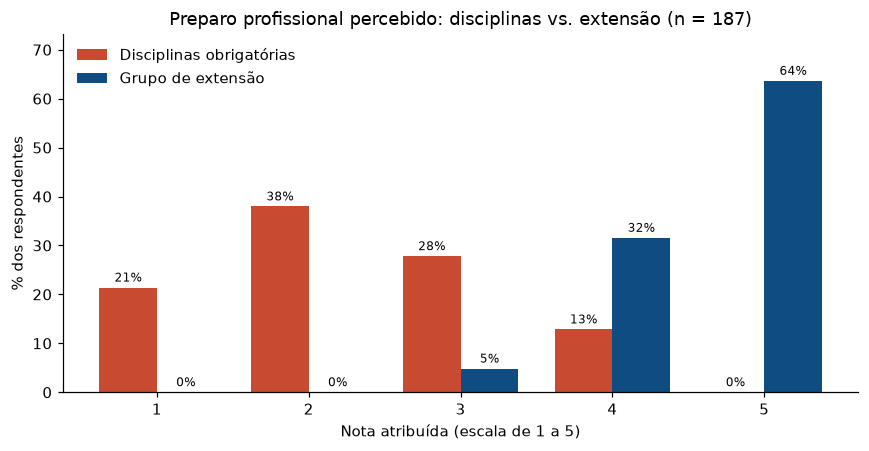

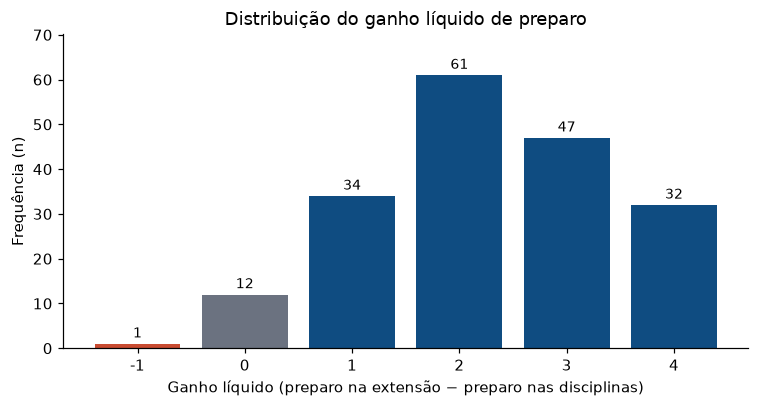

In [7]:
plot_likert_comparison(df, FIG_DIR / "01_distribuicao_preparo.png")
plot_delta_distribution(df, FIG_DIR / "02_distribuicao_ganho_liquido.png")

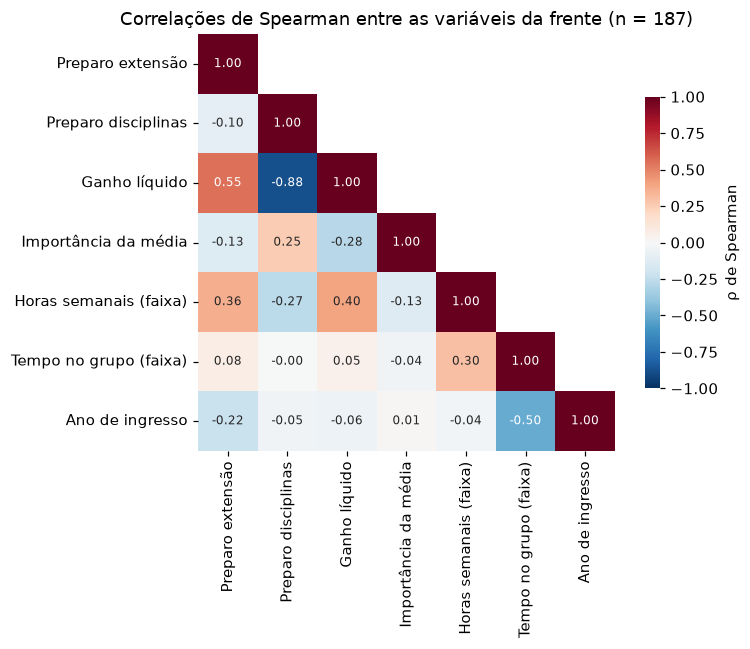

,Preparo extensão,Preparo disciplinas,Ganho líquido,Importância da média,Horas semanais (faixa),Tempo no grupo (faixa),Ano de ingresso
Preparo extensão,1.00,-0.10,0.55,-0.13,0.36,0.08,-0.22
Preparo disciplinas,-0.10,1.00,-0.88,0.25,-0.27,-0.00,-0.05
Ganho líquido,0.55,-0.88,1.00,-0.28,0.40,0.05,-0.06
Importância da média,-0.13,0.25,-0.28,1.00,-0.13,-0.04,0.01
Horas semanais (faixa),0.36,-0.27,0.40,-0.13,1.00,0.30,-0.04
Tempo no grupo (faixa),0.08,-0.00,0.05,-0.04,0.30,1.00,-0.50
Ano de ingresso,-0.22,-0.05,-0.06,0.01,-0.04,-0.50,1.00


In [8]:
CORR_LABELS = {
    "preparo_extensao": "Preparo extensão",
    "preparo_disciplinas": "Preparo disciplinas",
    "delta_preparo": "Ganho líquido",
    "importancia_media": "Importância da média",
    "horas_ord": "Horas semanais (faixa)",
    "tempo_ord": "Tempo no grupo (faixa)",
    "ano_ingresso": "Ano de ingresso",
}
spearman = df[list(CORR_LABELS)].corr(method="spearman").rename(index=CORR_LABELS, columns=CORR_LABELS)
plot_spearman_heatmap(spearman, "Correlações de Spearman entre as variáveis da frente (n = 187)",
                      FIG_DIR / "03_correlacoes_spearman.png")
spearman.round(2)

In [9]:
print("Categoria do grupo × grande área do curso")
display(pd.crosstab(df["categoria_extensao"], df["grande_area_curso"], margins=True, margins_name="Total"))
print("Categoria do grupo × horas semanais no grupo")
display(pd.crosstab(df["categoria_extensao"], df["horas_semanais_grupo"], margins=True, margins_name="Total"))
print("Grupo × categoria (n por grupo)")
display(df.groupby(["categoria_extensao", "grupo_extensao"], observed=True).size().rename("n").to_frame())

Categoria do grupo × grande área do curso


grande_area_curso,Civil & Ambiental,Elétrica & Computação,"Mecânica, Mecatrônica & Naval",Produção,Outras Engenharias,Total
categoria_extensao,,,,,,
Consultoria & Negócios,33,26,10,17,14,100
Engenharia,0,19,25,0,1,45
Mercado Financeiro,11,6,5,10,2,34
Empreendedorismo,2,0,1,1,4,8
Total,46,51,41,28,21,187


Categoria do grupo × horas semanais no grupo


horas_semanais_grupo,1 a 5h,6 a 10h,11 a 20h,21 a 40h,Mais de 40h,Total
categoria_extensao,,,,,,
Consultoria & Negócios,3,10,30,40,17,100
Engenharia,5,20,12,7,1,45
Mercado Financeiro,11,10,4,1,8,34
Empreendedorismo,2,3,3,0,0,8
Total,21,43,49,48,26,187


Grupo × categoria (n por grupo)


n
categoria_extensao     grupo_extensao                      
Consultoria & Negócios Grupo de Negócios da Poli         15
                       Poli Consulting Club              10
                       Poli Júnior                       75
Engenharia             Poli Racing                       16
                       Thunder Ratz                      29
Mercado Financeiro     Poli Finance                       9
                       Poli Quant                        13
                       Poli Real State                   12
Empreendedorismo       Liga de Empreendedorismo da Poli   8

**Leitura descritiva.**

- **Preparo na extensão:** mediana 5; 95,2% dão nota ≥ 4 e 63,6% dão nota 5; ninguém deu 1 ou 2. O efeito teto está confirmado.
- **Preparo nas disciplinas:** mediana 2; só 12,8% dão nota ≥ 4 e ninguém deu 5. As duas distribuições quase não se sobrepõem (figura 1).
- **Ganho líquido:** média 2,27 (DP 1,17); 93,0% positivo, 6,4% zero e um único caso negativo.
- **Importância da média:** distribuição centrada (mediana 3, média 2,93). É a única das quatro variáveis com dispersão razoável para os dois lados.
- **Correlações de Spearman (figura 3 e matriz acima):**
  - o ganho líquido é quase o espelho do preparo nas disciplinas (ρ = −0,88) e só moderadamente ligado ao preparo na extensão (ρ = 0,55), o que confirma o cuidado 4;
  - as horas semanais se correlacionam com o preparo na extensão (+0,36) e, negativamente, com o das disciplinas (−0,27);
  - o tempo de grupo se correlaciona sobretudo com o ano de ingresso (−0,50) e com as horas (+0,30).
- **Composição:**
  - Consultoria & Negócios concentra 57 dos 74 alunos que dedicam mais de 20 h por semana (40 + 17 na tabela categoria × horas);
  - Engenharia não tem alunos de Civil & Ambiental nem de Produção;
  - a Poli Júnior sozinha é 75% de Consultoria & Negócios.

  Essas sobreposições motivam os controles de confundimento das seções seguintes.

In [10]:
# Registry of the primary test of each question (Holm correction in Section 11)
primary_tests = []


def dunn_table(data, value, group):
    """Dunn post-hoc with PT-BR headers for display."""
    return dunn_test(data, value, group).rename(
        columns={"group_1": "Grupo 1", "group_2": "Grupo 2", "p_raw": "p bruto", "p_adj": "p Holm"})


def register(question, test, statistic, p_value, effect):
    primary_tests.append({"Pergunta": question, "Teste primário": test, "Estatística": statistic,
                          "p": p_value, "Tamanho de efeito": effect})

## 3. P1 — A extensão prepara mais do que as disciplinas obrigatórias?

**(a) Pergunta e hipóteses.** Para cada aluno *i*, seja $d_i$ = `preparo_extensao` − `preparo_disciplinas`.

- $H_0$: a distribuição de $d_i$ é simétrica em torno de zero (não há diferença sistemática entre os dois preparos percebidos).
- $H_1$: a distribuição de $d_i$ não é centrada em zero (teste bilateral; a direção é lida pelo sinal).

**(b) Teste e premissas.** Teste de postos sinalizados de Wilcoxon pareado (primário). Premissas: pares independentes entre si (um aluno por linha ✔), escala ao menos ordinal com diferenças comparáveis (aproximação usual para Likert) e simetria de $d_i$ em torno da mediana (checada pela assimetria amostral). Robustez: (i) teste do sinal exato, que não exige simetria; (ii) Wilcoxon-Pratt, que mantém os empates $d_i = 0$; (iii) t pareado, válido aqui pelo TCL (n = 187). Tamanhos de efeito: correlação rank-bisserial pareada ($r_{rb}$), $d_z$ de Cohen e proporção de $d_i > 0$.

In [11]:
p1 = paired_comparison(df["preparo_extensao"], df["preparo_disciplinas"], n_boot=N_BOOT, seed=SEED)
d = df["preparo_extensao"] - df["preparo_disciplinas"]
print(f"Assimetria amostral de d: {stats.skew(d):.3f} (|valor| < 0,5 → aproximadamente simétrica)")

p1_summary = pd.Series({
    "n de pares": p1["n"],
    "d > 0 / d = 0 / d < 0": f'{p1["n_positive"]} / {p1["n_zero"]} / {p1["n_negative"]}',
    "Média de d [IC 95% t]": f'{p1["mean_diff"]:.2f} [{p1["mean_diff_ci95_t"][0]:.2f}; {p1["mean_diff_ci95_t"][1]:.2f}]',
    "Média de d [IC 95% bootstrap BCa]": f'{p1["mean_diff"]:.2f} [{p1["mean_diff_ci95_boot"][0]:.2f}; {p1["mean_diff_ci95_boot"][1]:.2f}]',
    "Mediana de d": f'{p1["median_diff"]:.0f}',
    "Wilcoxon: W (zeros descartados)": f'{p1["wilcoxon_W"]:.0f}',
    "Wilcoxon: p": f'{p1["wilcoxon_p"]:.1e}',
    "Wilcoxon-Pratt (zeros mantidos): p": f'{p1["wilcoxon_pratt_p"]:.1e}',
    "Correlação rank-bisserial pareada": f'{p1["rank_biserial"]:.3f}',
    "Teste do sinal exato: p": f'{p1["sign_test_p"]:.1e}',
    "t pareado (gl)": f'{p1["t_stat"]:.2f} ({p1["t_df"]})',
    "t pareado: p": f'{p1["t_p"]:.1e}',
    "d de Cohen (d_z)": f'{p1["cohen_dz"]:.2f}',
}, name="P1: extensão vs. disciplinas").to_frame()
register("P1", "Wilcoxon pareado", f'W = {p1["wilcoxon_W"]:.0f}', p1["wilcoxon_p"], f'r_rb = {p1["rank_biserial"]:.3f}')
p1_summary.to_csv(TAB_DIR / "p1_teste_pareado.csv")
p1_summary

Assimetria amostral de d: -0.205 (|valor| < 0,5 → aproximadamente simétrica)


,P1: extensão vs. disciplinas
n de pares,187
d > 0 / d = 0 / d < 0,174 / 12 / 1
Média de d [IC 95% t],2.27 [2.10; 2.44]
Média de d [IC 95% bootstrap BCa],2.27 [2.10; 2.44]
Mediana de d,2
Wilcoxon: W (zeros descartados),18
Wilcoxon: p,7.0e-31
Wilcoxon-Pratt (zeros mantidos): p,1.9e-32
Correlação rank-bisserial pareada,0.998
Teste do sinal exato: p,7.4e-51


**Consistência por subgrupo.** Para saber se o resultado não é produzido por um único grupo dominante (ex.: Poli Júnior), repito o teste dentro de cada grande área e de cada categoria, com Holm dentro de cada variável.

In [12]:
rows = []
for var, label in [("grande_area_curso", "Grande área"), ("categoria_extensao", "Categoria do grupo")]:
    for level, sub in df.groupby(var, observed=True):
        r = paired_comparison(sub["preparo_extensao"], sub["preparo_disciplinas"], n_boot=N_BOOT, seed=SEED)
        rows.append({
            "Variável": label,
            "Grupo": level,
            "n": r["n"],
            "% d > 0": 100 * r["n_positive"] / r["n"],
            "% d < 0": 100 * r["n_negative"] / r["n"],
            "Média de d": r["mean_diff"],
            "IC 95% bootstrap": f'[{r["mean_diff_ci95_boot"][0]:.2f}; {r["mean_diff_ci95_boot"][1]:.2f}]',
            "r_rb": r["rank_biserial"],
            "p Wilcoxon": r["wilcoxon_p"],
        })
p1_subgroups = pd.DataFrame(rows)
p1_subgroups["p Holm"] = p1_subgroups.groupby("Variável")["p Wilcoxon"].transform(lambda s: adjust_pvalues(s.to_numpy()))
p1_subgroups.to_csv(TAB_DIR / "p1_subgrupos.csv", index=False)
p1_subgroups.round(3)

,Variável,Grupo,n,% d > 0,% d < 0,Média de d,IC 95% bootstrap,r_rb,p Wilcoxon,p Holm
0,Grande área,Civil & Ambiental,46,93.478,2.174,2.109,[1.76; 2.43],0.988,0.00,0.00
1,Grande área,Elétrica & Computação,51,92.157,0.000,2.235,[1.92; 2.55],1.000,0.00,0.00
2,Grande área,"Mecânica, Mecatrônica & Naval",41,85.366,0.000,1.976,[1.59; 2.37],1.000,0.00,0.00
3,Grande área,Produção,28,100.000,0.000,2.679,[2.32; 3.04],1.000,0.00,0.00
4,Grande área,Outras Engenharias,21,100.000,0.000,2.714,[2.33; 3.05],1.000,0.00,0.00
5,Categoria do grupo,Consultoria & Negócios,100,95.000,1.000,2.590,[2.35; 2.80],0.997,0.00,0.00
6,Categoria do grupo,Engenharia,45,84.444,0.000,1.622,[1.31; 1.93],1.000,0.00,0.00
7,Categoria do grupo,Mercado Financeiro,34,97.059,0.000,2.176,[1.85; 2.50],1.000,0.00,0.00
8,Categoria do grupo,Empreendedorismo,8,100.000,0.000,2.250,[1.75; 2.62],1.000,0.01,0.01


**(c) Resultado.**

- **Teste primário:** Wilcoxon W = 18, p = 7,0 × 10⁻³¹; correlação rank-bisserial r_rb = 0,998; d de Cohen d_z = 1,95.
- **Distribuição das diferenças:** 174 de 187 (93,0%) dão nota maior à extensão, 12 (6,4%) empatam e 1 (0,5%) dá nota maior às disciplinas. Diferença média de 2,27 pontos (IC 95%: 2,10 a 2,44, igual pelo t e pelo bootstrap BCa).
- **Premissa de simetria:** razoável (assimetria de d = −0,21).
- **Testes de robustez:** teste do sinal, Wilcoxon-Pratt e t pareado concordam, todos com p < 10⁻³⁰.
- **Subgrupos:** o resultado se repete em cada uma das 5 grandes áreas e das 4 categorias (p de Holm ≤ 0,011, sendo o maior o de Empreendedorismo, com n = 8; entre 84% e 100% com d > 0 em cada subgrupo). Não é um efeito produzido só pela Poli Júnior.

**(d)** Figuras 1 e 2, tabela `p1_subgrupos.csv`.

**(e) Conclusão para o relatório.** Os participantes de grupos de extensão percebem um preparo profissional muito maior na extensão do que nas disciplinas obrigatórias: mediana 5 contra 2, diferença média de 2,3 pontos (IC 95%: 2,1 a 2,4; Wilcoxon p < 10⁻³⁰; r_rb ≈ 1). A percepção é quase unânime (93% favorecem a extensão e apenas 0,5% as disciplinas) e se repete em todas as áreas de curso e categorias de grupo. Como é uma autoavaliação feita só por participantes, o resultado mede *percepção relativa* entre quem está na extensão, e não um efeito causal da extensão.

## 4. P2 — O ganho líquido se mantém em todas as grandes áreas?

**(a) Pergunta e hipóteses.** Duas partes:

- **P2a** (o ganho existe em cada área?): já respondida na tabela de subgrupos da P1 — teste de Wilcoxon dentro de cada área, com Holm.
- **P2b** (o tamanho do ganho difere entre áreas?): $H_0$: a distribuição de `delta_preparo` é a mesma nas 5 grandes áreas; $H_1$: ao menos uma área difere. Para responder à parte "há áreas em que a grade supre melhor o preparo?", a mesma hipótese é testada para `preparo_disciplinas` (e para `preparo_extensao`, para completar a decomposição).

**(b) Teste e premissas.** Kruskal-Wallis com correção de empates (primário: `delta_preparo`), tamanho de efeito ε²; post-hoc de Dunn com Holm. Premissas: amostras independentes ✔, variável ao menos ordinal ✔; para interpretar como diferença de *posição* é desejável formato semelhante entre grupos (checado com o teste de Levene, que também valida a ANOVA de Welch usada como robustez). **Controle de confundimento:** como a categoria do grupo está desbalanceada entre áreas, ajusto um modelo logístico ordinal de `preparo_disciplinas` com área **e** categoria e testo a área condicionada à categoria (teste da razão de verossimilhança, LR).

> Atenção: "Outras Engenharias" junta Materiais/Metalúrgica/Nuclear (12), Minas/Petróleo (7) e Química (2) — é um grupo heterogêneo, e diferenças envolvendo-o são difíceis de interpretar.

In [13]:
def compare_groups(data, group, outcomes):
    rows = []
    for col, label in outcomes:
        kw = kruskal_with_effect(data, col, group)
        wa = welch_anova(data, col, group)
        rows.append({
            "Variável": label, "n": kw["n"], "H (gl)": f'{kw["H"]:.2f} ({kw["df"]})', "p Kruskal-Wallis": kw["p"],
            "ε²": kw["epsilon_sq"], "F de Welch (gl)": f'{wa["F"]:.2f} ({wa["df1"]}; {wa["df2"]:.1f})',
            "p Welch": wa["p"], "ω²": wa["omega_sq"], "p Levene": wa["levene_p"],
        })
    return pd.DataFrame(rows).set_index("Variável")


DECOMPOSITION = [
    ("delta_preparo", "Ganho líquido"),
    ("preparo_disciplinas", "Preparo nas disciplinas"),
    ("preparo_extensao", "Preparo na extensão"),
]
p2 = compare_groups(df, "grande_area_curso", DECOMPOSITION)
kw = kruskal_with_effect(df, "delta_preparo", "grande_area_curso")
register("P2", "Kruskal-Wallis: ganho líquido ~ grande área", f'H({kw["df"]}) = {kw["H"]:.2f}', kw["p"], f'ε² = {kw["epsilon_sq"]:.3f}')
p2.to_csv(TAB_DIR / "p2_area_kruskal.csv")
p2.round(4)

,n,H (gl),p Kruskal-Wallis,ε²,F de Welch (gl),p Welch,ω²,p Levene
Variável,,,,,,,,
Ganho líquido,187,9.66 (4),0.0465,0.0519,3.12 (4; 80.1),0.0195,0.0330,0.2589
Preparo nas disciplinas,187,10.23 (4),0.0368,0.0550,4.45 (4; 81.3),0.0027,0.0348,0.1270
Preparo na extensão,187,4.96 (4),0.2915,0.0267,1.73 (4; 79.4),0.1513,0.0027,0.3459


In [14]:
print("Composição de 'Outras Engenharias':", df.loc[df["grande_area_curso"] == "Outras Engenharias", "curso"].value_counts().loc[lambda s: s > 0].to_dict())
print("Médias por grande área")
display(df.groupby("grande_area_curso", observed=True)[[c for c, _ in DECOMPOSITION]].agg(["mean", "count"]).round(2))
print("Dunn (Holm) — ganho líquido")
display(dunn_table(df, "delta_preparo", "grande_area_curso").round(4))
print("Dunn (Holm) — preparo nas disciplinas")
display(dunn_table(df, "preparo_disciplinas", "grande_area_curso").round(4))

Composição de 'Outras Engenharias': {'Engenharia de Materiais/Metalúrgica/Nuclear': 12, 'Engenharia de Minas/Petróleo': 7, 'Engenharia Química': 2}
Médias por grande área


delta_preparo       preparo_disciplinas       preparo_extensao      
                                       mean count                mean count             mean count
grande_area_curso                                                                                 
Civil & Ambiental                      2.11    46                2.43    46             4.54    46
Elétrica & Computação                  2.24    51                2.37    51             4.61    51
Mecânica, Mecatrônica & Naval          1.98    41                2.54    41             4.51    41
Produção                               2.68    28                2.11    28             4.79    28
Outras Engenharias                     2.71    21                1.81    21             4.52    21

Dunn (Holm) — ganho líquido


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Civil & Ambiental,Elétrica & Computação,-0.5153,0.6063,1.0000
1,Civil & Ambiental,"Mecânica, Mecatrônica & Naval",0.4790,0.6319,1.0000
2,Civil & Ambiental,Produção,-1.9359,0.0529,0.3702
3,Civil & Ambiental,Outras Engenharias,-2.0460,0.0408,0.3260
4,Elétrica & Computação,"Mecânica, Mecatrônica & Naval",0.9900,0.3222,1.0000
5,Elétrica & Computação,Produção,-1.5274,0.1267,0.6334
6,Elétrica & Computação,Outras Engenharias,-1.6741,0.0941,0.5647
7,"Mecânica, Mecatrônica & Naval",Produção,-2.3124,0.0208,0.1868
8,"Mecânica, Mecatrônica & Naval",Outras Engenharias,-2.3914,0.0168,0.1678
9,Produção,Outras Engenharias,-0.2592,0.7955,1.0000


Dunn (Holm) — preparo nas disciplinas


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Civil & Ambiental,Elétrica & Computação,0.2300,0.8181,1.0000
1,Civil & Ambiental,"Mecânica, Mecatrônica & Naval",-0.6652,0.5059,1.0000
2,Civil & Ambiental,Produção,1.2411,0.2146,1.0000
3,Civil & Ambiental,Outras Engenharias,2.4283,0.0152,0.1365
4,Elétrica & Computação,"Mecânica, Mecatrônica & Naval",-0.9041,0.3660,1.0000
5,Elétrica & Computação,Produção,1.0659,0.2865,1.0000
6,Elétrica & Computação,Outras Engenharias,2.2861,0.0222,0.1780
7,"Mecânica, Mecatrônica & Naval",Produção,1.7962,0.0725,0.5073
8,"Mecânica, Mecatrônica & Naval",Outras Engenharias,2.9156,0.0036,0.0355
9,Produção,Outras Engenharias,1.1848,0.2361,1.0000


In [15]:
X_area = pd.get_dummies(df[["grande_area_curso"]], drop_first=True)
X_category = pd.get_dummies(df[["categoria_extensao"]], drop_first=True)
m_both = fit_ordinal_logit(df["preparo_disciplinas"], pd.concat([X_category, X_area], axis=1))
m_area_only = fit_ordinal_logit(df["preparo_disciplinas"], X_area)
m_category_only = fit_ordinal_logit(df["preparo_disciplinas"], X_category)

confounding = pd.DataFrame([
    {"Teste (preparo nas disciplinas)": "Área, sem controle", **likelihood_ratio_test(m_area_only.llf, ordinal_null_loglik(df["preparo_disciplinas"]), X_area.shape[1])},
    {"Teste (preparo nas disciplinas)": "Área | categoria", **likelihood_ratio_test(m_both.llf, m_category_only.llf, X_area.shape[1])},
    {"Teste (preparo nas disciplinas)": "Categoria, sem controle", **likelihood_ratio_test(m_category_only.llf, ordinal_null_loglik(df["preparo_disciplinas"]), X_category.shape[1])},
    {"Teste (preparo nas disciplinas)": "Categoria | área", **likelihood_ratio_test(m_both.llf, m_area_only.llf, X_category.shape[1])},
]).set_index("Teste (preparo nas disciplinas)")
confounding.to_csv(TAB_DIR / "p2_p3_confundimento_area_categoria.csv")
confounding.round(4)

,LR,df,p
Teste (preparo nas disciplinas),,,
"Área, sem controle",9.7231,4,0.0454
Área | categoria,7.3690,4,0.1176
"Categoria, sem controle",25.3940,3,0.0000
Categoria | área,23.0399,3,0.0000


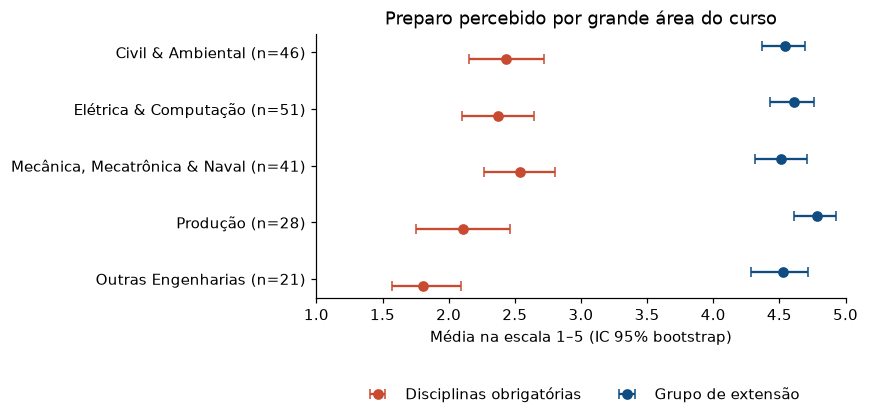

In [16]:
ext_by_area = bootstrap_group_means(df, "preparo_extensao", "grande_area_curso", n_boot=N_BOOT, seed=SEED)
disc_by_area = bootstrap_group_means(df, "preparo_disciplinas", "grande_area_curso", n_boot=N_BOOT, seed=SEED)
plot_group_means(ext_by_area, disc_by_area, "grande_area_curso",
                 "Preparo percebido por grande área do curso", FIG_DIR / "04_preparo_por_area.png", order=AREA_ORDER)

**(c) Resultado.**

- **P2a (o ganho existe em cada área?):** sim. O ganho é positivo e significativo em todas as 5 áreas (p de Holm < 0,001; entre 85% e 100% com d > 0).
- **P2b (o tamanho do ganho difere entre áreas?):**
  - Kruskal-Wallis H(4) = 9,66, p = 0,047, ε² = 0,05 (efeito pequeno). Nenhum par de áreas difere no Dunn com Holm para o ganho (menor p ajustado = 0,17).
  - A variação vem das disciplinas (H(4) = 10,23, p = 0,037), não da extensão (p = 0,29).
  - Nas disciplinas, um único par chega a ser significativo após Holm: Mecânica, Mecatrônica & Naval (2,54) contra Outras Engenharias (1,81), p = 0,036. "Outras Engenharias" é um agrupamento heterogêneo (Materiais/Metalúrgica/Nuclear, Minas/Petróleo e Química), então esse contraste é tratado como exploratório.
- **Controle de confundimento:** ao controlar a categoria do grupo, o sinal da área diminui e perde significância (LR de 9,7 para 7,4, gl 4; p de 0,045 para 0,12). Já o efeito da categoria persiste com controle da área (LR = 23,0, gl 3, p < 0,001).
- **Após Holm na família de testes (Seção 11):** a P2b não é significativa (p ≈ 0,19).

**(d)** Figura 4, tabelas `p2_area_kruskal.csv` e `p2_p3_confundimento_area_categoria.csv`.

**(e) Conclusão para o relatório.** O ganho de preparo da extensão sobre a grade aparece em todas as grandes áreas de curso. As diferenças entre áreas são pequenas (ε² = 0,05; p = 0,047, não significativo após a correção de Holm) e vêm da avaliação das disciplinas. Parte delas acompanha a composição das categorias de grupo em cada área: com esse controle, o efeito da área perde significância (p = 0,12). Com esta amostra, não há evidência robusta de que alguma grade curricular supra melhor o preparo profissional percebido. O único contraste pontual (Mecânica, Mecatrônica & Naval acima de "Outras Engenharias") envolve um grupo heterogêneo e é exploratório.

## 5. P3 — O preparo e o ganho líquido variam entre categorias de grupo de extensão?

**(a) Pergunta e hipóteses.** Primários: $H_0^{(\Delta)}$: a distribuição de `delta_preparo` é igual nas 4 categorias; $H_0^{(ext)}$: a distribuição de `preparo_extensao` é igual nas 4 categorias. $H_1$: ao menos uma categoria difere (em cada caso). Decomposição: a mesma hipótese para `preparo_disciplinas`.

**(b) Teste e premissas.** Kruskal-Wallis + ε², Dunn com Holm, Welch como robustez (mesmas premissas da P2). Cuidados específicos: (i) "Empreendedorismo" tem n = 8 → análise de sensibilidade sem essa categoria; (ii) confundimento com a área do curso → análise **estratificada** dentro das duas áreas onde Engenharia e Consultoria coexistem (Elétrica & Computação; Mecânica, Mecatrônica & Naval) e teste LR da categoria condicionada à área (tabela da P2).

In [17]:
p3 = compare_groups(df, "categoria_extensao", DECOMPOSITION)
for col, label in [("delta_preparo", "ganho líquido"), ("preparo_extensao", "preparo na extensão")]:
    kw = kruskal_with_effect(df, col, "categoria_extensao")
    register(f"P3 ({label})", f"Kruskal-Wallis: {label} ~ categoria", f'H({kw["df"]}) = {kw["H"]:.2f}', kw["p"], f'ε² = {kw["epsilon_sq"]:.3f}')
p3.to_csv(TAB_DIR / "p3_categoria_kruskal.csv")
p3.round(4)

,n,H (gl),p Kruskal-Wallis,ε²,F de Welch (gl),p Welch,ω²,p Levene
Variável,,,,,,,,
Ganho líquido,187,22.48 (3),0.0001,0.1209,7.68 (3; 33.1),0.0005,0.1015,0.2906
Preparo nas disciplinas,187,23.98 (3),0.0000,0.1289,8.49 (3; 30.6),0.0003,0.1073,0.5622
Preparo na extensão,187,5.64 (3),0.1307,0.0303,1.57 (3; 30.2),0.2174,0.0087,0.3201


In [18]:
print("Médias por categoria")
display(df.groupby("categoria_extensao", observed=True)[[c for c, _ in DECOMPOSITION]].agg(["mean", "count"]).round(2))
print("Dunn (Holm) — ganho líquido")
display(dunn_table(df, "delta_preparo", "categoria_extensao").round(5))
print("Dunn (Holm) — preparo nas disciplinas")
display(dunn_table(df, "preparo_disciplinas", "categoria_extensao").round(5))
print("Sensibilidade: sem a categoria Empreendedorismo (n = 8)")
display(compare_groups(df[df["categoria_extensao"] != "Empreendedorismo"].assign(
    categoria_extensao=lambda x: x["categoria_extensao"].cat.remove_unused_categories()), "categoria_extensao", DECOMPOSITION).round(5))

Médias por categoria


delta_preparo       preparo_disciplinas       preparo_extensao      
                                mean count                mean count             mean count
categoria_extensao                                                                         
Consultoria & Negócios          2.59   100                2.08   100             4.67   100
Engenharia                      1.62    45                2.89    45             4.51    45
Mercado Financeiro              2.18    34                2.32    34             4.50    34
Empreendedorismo                2.25     8                2.12     8             4.38     8

Dunn (Holm) — ganho líquido


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Consultoria & Negócios,Engenharia,4.69664,0.00000,0.00002
1,Consultoria & Negócios,Mercado Financeiro,1.93390,0.05313,0.21660
2,Consultoria & Negócios,Empreendedorismo,0.86684,0.38603,0.77206
3,Engenharia,Mercado Financeiro,-2.02062,0.04332,0.21660
4,Engenharia,Empreendedorismo,-1.36717,0.17157,0.51472
5,Mercado Financeiro,Empreendedorismo,-0.16650,0.86776,0.86776


Dunn (Holm) — preparo nas disciplinas


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Consultoria & Negócios,Engenharia,-4.84499,0.00000,0.00001
1,Consultoria & Negócios,Mercado Financeiro,-1.48167,0.13843,0.41528
2,Consultoria & Negócios,Empreendedorismo,-0.05950,0.95255,0.97672
3,Engenharia,Mercado Financeiro,2.53291,0.01131,0.05656
4,Engenharia,Empreendedorismo,2.20967,0.02713,0.10851
5,Mercado Financeiro,Empreendedorismo,0.69292,0.48836,0.97672


Sensibilidade: sem a categoria Empreendedorismo (n = 8)


,n,H (gl),p Kruskal-Wallis,ε²,F de Welch (gl),p Welch,ω²,p Levene
Variável,,,,,,,,
Ganho líquido,179,21.92 (2),0.00002,0.12317,11.89 (2; 82.0),0.00003,0.10753,0.44865
Preparo nas disciplinas,179,23.12 (2),0.00001,0.12986,12.90 (2; 80.7),0.00001,0.11365,0.76721
Preparo na extensão,179,3.78 (2),0.15072,0.02126,1.68 (2; 73.2),0.19369,0.00822,0.17822


**Análise estratificada.** Comparação Engenharia × Consultoria & Negócios *dentro* da mesma área de curso (Mann-Whitney por estrato, Holm entre os 4 testes; efeito = correlação rank-bisserial, positiva quando Engenharia > Consultoria).

In [19]:
STRATA = ["Elétrica & Computação", "Mecânica, Mecatrônica & Naval"]
strata_df = df[df["grande_area_curso"].isin(STRATA) & df["categoria_extensao"].isin(["Engenharia", "Consultoria & Negócios"])]
rows = []
for area in STRATA:
    sub = strata_df[strata_df["grande_area_curso"] == area]
    eng = sub[sub["categoria_extensao"] == "Engenharia"]
    cons = sub[sub["categoria_extensao"] == "Consultoria & Negócios"]
    for col, label in [("preparo_disciplinas", "Preparo nas disciplinas"), ("delta_preparo", "Ganho líquido")]:
        mw = stats.mannwhitneyu(eng[col], cons[col], alternative="two-sided")
        rows.append({
            "Área": area, "Variável": label, "n Engenharia": len(eng), "n Consultoria": len(cons),
            "Média Engenharia": eng[col].mean(), "Média Consultoria": cons[col].mean(),
            "U": mw.statistic, "r_rb": 2 * mw.statistic / (len(eng) * len(cons)) - 1, "p": mw.pvalue,
        })
p3_strata = pd.DataFrame(rows)
p3_strata["p Holm"] = adjust_pvalues(p3_strata["p"].to_numpy())
p3_strata.to_csv(TAB_DIR / "p3_estratificado_por_area.csv", index=False)
p3_strata.round(4)

,Área,Variável,n Engenharia,n Consultoria,Média Engenharia,Média Consultoria,U,r_rb,p,p Holm
0,Elétrica & Computação,Preparo nas disciplinas,19,26,2.8421,2.0000,364.0,0.4737,0.0053,0.0124
1,Elétrica & Computação,Ganho líquido,19,26,1.7368,2.7308,125.5,-0.4919,0.0041,0.0124
2,"Mecânica, Mecatrônica & Naval",Preparo nas disciplinas,25,10,2.9600,1.8000,208.0,0.6640,0.0014,0.0055
3,"Mecânica, Mecatrônica & Naval",Ganho líquido,25,10,1.4800,2.9000,50.5,-0.5960,0.0057,0.0124


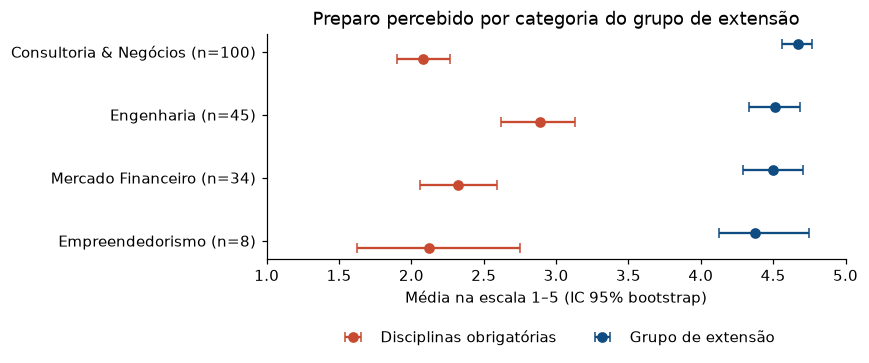

In [20]:
ext_by_cat = bootstrap_group_means(df, "preparo_extensao", "categoria_extensao", n_boot=N_BOOT, seed=SEED)
disc_by_cat = bootstrap_group_means(df, "preparo_disciplinas", "categoria_extensao", n_boot=N_BOOT, seed=SEED)
plot_group_means(ext_by_cat, disc_by_cat, "categoria_extensao",
                 "Preparo percebido por categoria do grupo de extensão", FIG_DIR / "05_preparo_por_categoria.png",
                 order=CATEGORY_ORDER)

**(c) Resultado.**

- **Ganho líquido (primário):** difere entre categorias. H(3) = 22,48, p = 5,2 × 10⁻⁵, ε² = 0,12 (efeito médio). O único par significativo é Engenharia × Consultoria & Negócios (Dunn, p de Holm = 2 × 10⁻⁵): 1,62 contra 2,59 pontos.
- **Preparo na extensão (primário):** sem diferença significativa. H(3) = 5,64, p = 0,13; médias entre 4,38 e 4,67, com o teto da escala limitando o poder do teste.
- **Decomposição:** a diferença no ganho acompanha a das disciplinas. H(3) = 23,98, p = 2,5 × 10⁻⁵; Engenharia 2,89 contra Consultoria 2,08.
- **Robustez:**
  - o resultado se mantém sem a categoria Empreendedorismo;
  - também se mantém nas duas grandes áreas em que Engenharia e Consultoria coexistem: Elétrica & Computação (2,84 contra 2,00) e Mecânica, Mecatrônica & Naval (2,96 contra 1,80), p de Holm ≤ 0,013, |r_rb| entre 0,47 e 0,66;
  - e no modelo ordinal com área (LR categoria | área = 23,0, p < 0,001).
- **Empreendedorismo** (n = 8) tem ICs largos (figura 5); suas médias não devem ser comparadas isoladamente.

**(d)** Figura 5, tabelas `p3_categoria_kruskal.csv` e `p3_estratificado_por_area.csv`.

**(e) Conclusão para o relatório.** Os membros de grupos técnicos (Thunder Ratz, Poli Racing) têm um ganho líquido cerca de 1 ponto menor que os de Consultoria & Negócios (1,6 contra 2,6; ε² = 0,12). A diferença não está no preparo percebido na extensão, alto em todas as categorias e sem diferença significativa (p = 0,13). Está na avaliação das disciplinas obrigatórias, mais alta entre os grupos técnicos (2,9 contra 2,1). A diferença se mantém entre alunos da mesma grande área. Uma hipótese plausível, não testada aqui, é a complementaridade: em grupos técnicos o conteúdo da grade seria usado diretamente nos projetos, enquanto em grupos de negócios as competências exigidas ficariam mais distantes do currículo.

## 6. P4 — O preparo na extensão cresce com a dedicação (horas) e com o tempo de grupo? Há saturação?

**(a) Pergunta e hipóteses.**

- **P4a (horas):** $H_0$: τ-b(`horas_ord`, `preparo_extensao`) = 0; $H_1$: τ-b ≠ 0.
- **P4b (tempo):** $H_0$: τ-b(`tempo_ord`, `preparo_extensao`) = 0; $H_1$: τ-b ≠ 0.
- **P4c (saturação, complementar):** no modelo logístico de P(nota 5), $H_0$: o efeito das horas é linear no logito (tendência constante entre faixas); $H_1$: há desvio da linearidade (ex.: platô). Teste LR entre o modelo com horas como escore e com horas como fator.

**(b) Teste e premissas.** τ-b de Kendall (adequado a duas variáveis ordinais com muitos empates) com IC bootstrap; ρ de Spearman como robustez. Por causa do efeito teto, a forma da relação é examinada pela proporção de notas 5 por faixa (IC de Wilson). Confundimento: horas variam fortemente por categoria (Seção 2) → τ recalculado **dentro** de cada categoria e modelo com controle por categoria e por ano de ingresso (`tempo_grupo` e `ano_ingresso` são correlacionados, ρ ≈ −0,5).

In [21]:
p4_rows = []
for col, label in [("horas_ord", "Horas semanais (faixa)"), ("tempo_ord", "Tempo no grupo (faixa)")]:
    a = ordinal_association(df[col], df["preparo_extensao"], n_boot=N_BOOT, seed=SEED)
    p4_rows.append({
        "Variável": label, "n": a["n"], "τ-b de Kendall": a["kendall_tau_b"],
        "IC 95% τ (bootstrap)": f'[{a["kendall_ci95"][0]:.2f}; {a["kendall_ci95"][1]:.2f}]', "p Kendall": a["kendall_p"],
        "ρ de Spearman": a["spearman_rho"], "p Spearman": a["spearman_p"],
    })
    tag = "P4a (horas)" if col == "horas_ord" else "P4b (tempo de grupo)"
    register(tag, f"τ-b de Kendall: {label.lower()} × preparo na extensão", f'τ-b = {a["kendall_tau_b"]:.3f}', a["kendall_p"], f'τ-b = {a["kendall_tau_b"]:.2f}')
p4 = pd.DataFrame(p4_rows).set_index("Variável")
p4.to_csv(TAB_DIR / "p4_associacao_dedicacao.csv")
p4.round(4)

,n,τ-b de Kendall,IC 95% τ (bootstrap),p Kendall,ρ de Spearman,p Spearman
Variável,,,,,,
Horas semanais (faixa),187,0.3235,[0.22; 0.43],0.0000,0.3649,0.0000
Tempo no grupo (faixa),187,0.0722,[-0.06; 0.19],0.2915,0.0770,0.2946


In [22]:
rows = []
for cat, sub in df.groupby("categoria_extensao", observed=True):
    if len(sub) < 20:
        continue  # Empreendedorismo (n = 8) has too few observations for a stable estimate
    t_ext = stats.kendalltau(sub["horas_ord"], sub["preparo_extensao"])
    t_disc = stats.kendalltau(sub["horas_ord"], sub["preparo_disciplinas"])
    rows.append({"Categoria": cat, "n": len(sub), "τ-b horas × preparo extensão": t_ext.statistic, "p (extensão)": t_ext.pvalue,
                 "τ-b horas × preparo disciplinas": t_disc.statistic, "p (disciplinas)": t_disc.pvalue})
print("Associação com as horas DENTRO de cada categoria (controle do confundimento)")
within = pd.DataFrame(rows).set_index("Categoria")
within.to_csv(TAB_DIR / "p4_horas_dentro_da_categoria.csv")
within.round(4)

Associação com as horas DENTRO de cada categoria (controle do confundimento)


,n,τ-b horas × preparo extensão,p (extensão),τ-b horas × preparo disciplinas,p (disciplinas)
Categoria,,,,,
Consultoria & Negócios,100,0.2629,0.0039,-0.0936,0.2755
Engenharia,45,0.3386,0.0125,-0.1493,0.2505
Mercado Financeiro,34,0.4006,0.0099,-0.2748,0.0650


,level,n,k,prop,ci_low,ci_high
0,1 a 5h,21,8,0.381,0.208,0.591
1,6 a 10h,43,22,0.512,0.368,0.654
2,11 a 20h,49,26,0.531,0.394,0.663
3,21 a 40h,48,40,0.833,0.704,0.913
4,Mais de 40h,26,23,0.885,0.710,0.960


,level,n,k,prop,ci_low,ci_high
0,Menos de 6 meses,15,11,0.733,0.480,0.891
1,6 meses a 1 ano,84,49,0.583,0.477,0.683
2,1 a 2 anos,78,49,0.628,0.517,0.727
3,Mais de 2 anos,10,10,1.000,0.722,1.000


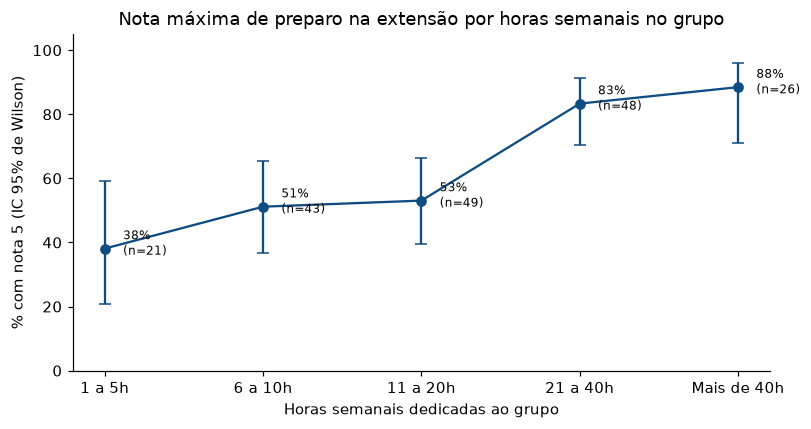

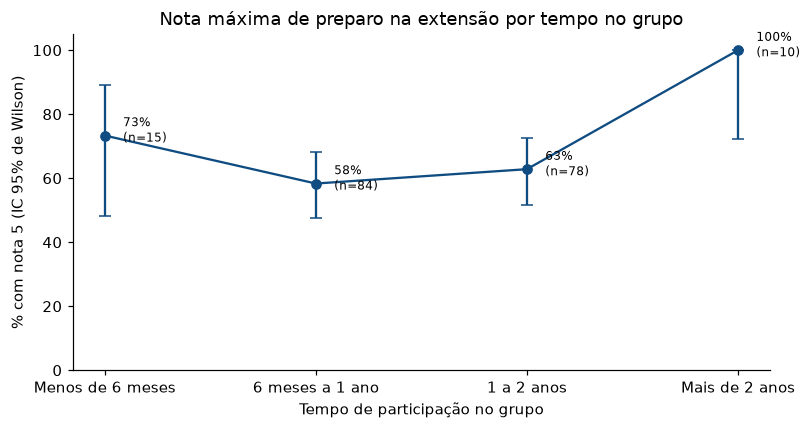

In [23]:
def proportion_table(data, level_col, success_col):
    rows = []
    for level, sub in data.groupby(level_col, observed=True):
        k, n = int(sub[success_col].sum()), len(sub)
        low, high = wilson_interval(k, n)
        rows.append({"level": str(level), "n": n, "k": k, "prop": k / n, "ci_low": low, "ci_high": high})
    return pd.DataFrame(rows)


top_by_hours = proportion_table(df, "horas_semanais_grupo", "preparo_ext_maximo")
top_by_time = proportion_table(df, "tempo_grupo", "preparo_ext_maximo")
display(top_by_hours.round(3))
display(top_by_time.round(3))
plot_proportion_by_level(top_by_hours, "Nota máxima de preparo na extensão por horas semanais no grupo",
                         "Horas semanais dedicadas ao grupo", "% com nota 5 (IC 95% de Wilson)",
                         FIG_DIR / "06_nota_maxima_por_horas.png")
plot_proportion_by_level(top_by_time, "Nota máxima de preparo na extensão por tempo no grupo",
                         "Tempo de participação no grupo", "% com nota 5 (IC 95% de Wilson)",
                         FIG_DIR / "07_nota_maxima_por_tempo.png")

In [24]:
df["horas_acima_20h"] = (df["horas_ord"] >= 4).astype(int)
saturation_models = {
    "Horas como escore linear": smf.logit("preparo_ext_maximo ~ horas_ord", df).fit(disp=False),
    "Horas como fator (5 faixas)": smf.logit("preparo_ext_maximo ~ C(horas_ord)", df).fit(disp=False),
    "Limiar: mais de 20 h (sim/não)": smf.logit("preparo_ext_maximo ~ horas_acima_20h", df).fit(disp=False),
}
saturation = pd.DataFrame({name: {"log-verossimilhança": m.llf, "gl do modelo": m.df_model, "AIC": m.aic, "BIC": m.bic}
                           for name, m in saturation_models.items()}).T
lr_nonlinear = likelihood_ratio_test(saturation_models["Horas como fator (5 faixas)"].llf,
                                     saturation_models["Horas como escore linear"].llf, 3)
print(f'LR (desvio da linearidade): LR = {lr_nonlinear["LR"]:.2f}, gl = 3, p = {lr_nonlinear["p"]:.3f}')
above, low = df[df["horas_ord"] >= 4], df[df["horas_ord"] == 1]
print(f'Nota máxima: acima de 20 h = {above["preparo_ext_maximo"].sum()}/{len(above)} ({above["preparo_ext_maximo"].mean():.0%}); '
      f'1 a 5 h = {low["preparo_ext_maximo"].sum()}/{len(low)} ({low["preparo_ext_maximo"].mean():.0%})')
saturation.round(2)

LR (desvio da linearidade): LR = 4.03, gl = 3, p = 0.258
Nota máxima: acima de 20 h = 63/74 (85%); 1 a 5 h = 8/21 (38%)


,log-verossimilhança,gl do modelo,AIC,BIC
Horas como escore linear,-110.56,1.0,225.12,231.58
Horas como fator (5 faixas),-108.55,4.0,227.09,243.25
Limiar: mais de 20 h (sim/não),-109.43,1.0,222.86,229.32


In [25]:
# Sensitivity: proportional-odds model with hours, time in group, category and (centered) entry year
X_p4 = pd.concat([
    df[["horas_ord", "tempo_ord"]].astype(float),
    (df["ano_ingresso"] - 2025).rename("ano_ingresso_centrado").astype(float),
    pd.get_dummies(df[["categoria_extensao"]], drop_first=True),
], axis=1)
m_p4 = fit_ordinal_logit(df["preparo_extensao"], X_p4)
p4_model = pd.DataFrame({"coef (log-odds)": m_p4.params, "erro padrão": m_p4.bse, "p": m_p4.pvalues,
                         "OR": np.exp(m_p4.params)}).loc[X_p4.columns]
p4_model.round(4)

,coef (log-odds),erro padrão,p,OR
horas_ord,0.8522,0.1842,0.0000,2.3448
tempo_ord,-0.9234,0.3338,0.0057,0.3972
ano_ingresso_centrado,-1.0594,0.2773,0.0001,0.3467
categoria_extensao_Engenharia,0.4594,0.4484,0.3056,1.5831
categoria_extensao_Mercado Financeiro,-0.3965,0.5237,0.4491,0.6727
categoria_extensao_Empreendedorismo,-0.5100,0.7657,0.5054,0.6005


**Exploratório — senioridade × tempo de grupo.** O modelo acima mostra o tempo de grupo com coeficiente *negativo* quando o ano de ingresso entra no modelo. Como `tempo_grupo` e `ano_ingresso` são fortemente correlacionados, isso pede investigação antes de qualquer interpretação: abaixo, a nota máxima por turma de ingresso e por tempo de grupo **dentro** da mesma turma. Esta análise não estava prevista e não entra na família corrigida.

In [26]:
seniority = df.assign(turma=df["ano_ingresso"].replace({2022: "2022–2023", 2023: "2022–2023"}).astype(str))
print("Proporção de nota máxima por turma de ingresso")
display(seniority.groupby("turma")["preparo_ext_maximo"].agg(prop="mean", n="size").round(2))
t_year = stats.kendalltau(df["ano_ingresso"], df["preparo_extensao"])
print(f"τ-b(ano de ingresso, preparo na extensão) = {t_year.statistic:.3f}, p = {t_year.pvalue:.4f}")
print()
print("Nota máxima por tempo de grupo dentro das duas maiores turmas")
display(seniority[seniority["turma"].isin(["2024", "2025"])]
        .groupby(["turma", "tempo_grupo"], observed=True)["preparo_ext_maximo"].agg(prop="mean", n="size").round(2))
for cohort in [2024, 2025]:
    sub = df[df["ano_ingresso"] == cohort]
    t = stats.kendalltau(sub["tempo_ord"], sub["preparo_extensao"])
    print(f"Turma {cohort}: τ-b(tempo de grupo, preparo na extensão) = {t.statistic:+.3f}, p = {t.pvalue:.3f}, n = {len(sub)}")
exog_p4 = np.column_stack([np.ones(len(X_p4)), X_p4.astype(float).to_numpy()])
print("VIF máximo no modelo de sensibilidade:", round(max(variance_inflation_factor(exog_p4, i) for i in range(1, exog_p4.shape[1])), 2))

Proporção de nota máxima por turma de ingresso


,prop,n
turma,,
2022–2023,0.67,9
2024,0.80,54
2025,0.60,93
2026,0.45,31


τ-b(ano de ingresso, preparo na extensão) = -0.207, p = 0.0022

Nota máxima por tempo de grupo dentro das duas maiores turmas


prop   n
turma tempo_grupo               
2024  Menos de 6 meses  1.00   1
      6 meses a 1 ano   0.79  14
      1 a 2 anos        0.75  32
      Mais de 2 anos    1.00   7
2025  Menos de 6 meses  0.70  10
      6 meses a 1 ano   0.63  43
      1 a 2 anos        0.55  40

Turma 2024: τ-b(tempo de grupo, preparo na extensão) = +0.099, p = 0.444, n = 54
Turma 2025: τ-b(tempo de grupo, preparo na extensão) = -0.105, p = 0.287, n = 93
VIF máximo no modelo de sensibilidade: 1.91


**(c) Resultado.**

- **Horas (P4a):** τ-b = 0,32 (IC 95%: 0,22 a 0,43), p = 5,7 × 10⁻⁷. É uma associação positiva moderada.
  - Ela também aparece dentro das 3 categorias com n ≥ 20 (τ-b de 0,26 a 0,40, todos p ≤ 0,013); Empreendedorismo (n = 8) ficou de fora dessa checagem.
  - A proporção de nota máxima passa de 38% (1–5 h) para 51–53% (6–20 h) e 83–88% (mais de 20 h); somando as duas faixas acima de 20 h, são 63/74 = 85%.
- **Tempo de grupo (P4b):** τ-b = 0,07 (IC 95%: −0,06 a 0,19), p = 0,29; não há associação significativa. Os 10 alunos com mais de 2 anos de grupo deram todos nota 5, mas n = 10 e há provável viés de sobrevivência (quem não gosta tende a sair antes).
- **Saturação (P4c):** o modelo linear no logito não é rejeitado (LR = 4,03, gl 3, p = 0,26). Um modelo de limiar em 20 h tem AIC um pouco menor (222,9 contra 225,1), mas esse corte foi escolhido olhando os dados, e uma diferença de AIC de cerca de 2 é evidência fraca.
- **Sensibilidade e análise exploratória:** com controle por categoria e ano de ingresso, as horas seguem fortes (OR = 2,3 por faixa).
  - Nesse modelo, o tempo de grupo aparece com coeficiente negativo e significativo (p = 0,006), sem multicolinearidade grave (VIF máximo = 1,9).
  - Porém o padrão não se repete de forma consistente dentro das turmas: τ-b(tempo, preparo) = +0,10 (p = 0,44) na turma de 2024 e −0,11 (p = 0,29) na de 2025, ambos não significativos.
  - Por isso, esse coeficiente condicional não é interpretado substantivamente; provavelmente reflete a forma como tempo de grupo e turma se combinam nesta amostra.
  - A nota máxima varia com a turma: 80% (2024), 60% (2025) e 45% (2026); a turma 2022–2023 (n = 9) tem 67% e quebra a monotonia. τ-b(ano, preparo) = −0,21, p = 0,002.
  - A senioridade no curso parece pesar mais que a permanência no grupo. Como esta análise é exploratória, fica como hipótese, inclusive para a Frente 3.

**(d)** Figuras 6 e 7, tabelas `p4_associacao_dedicacao.csv` e `p4_horas_dentro_da_categoria.csv`.

**(e) Conclusão para o relatório.** O preparo percebido na extensão está associado à dedicação semanal: acima de 20 h por semana, 85% dão nota máxima, contra 38% de quem dedica até 5 h (τ-b = 0,32; p < 0,001). A associação também aparece dentro das categorias de grupo com amostra suficiente. Já o tempo de permanência no grupo não mostrou associação significativa (τ-b = 0,07; p = 0,29). Não há evidência estatística de saturação: o aparente platô acima de 20 h coincide com o teto da escala, então os dados não distinguem saturação real de limite do instrumento. A direção causal é indeterminada, porque quem percebe mais retorno pode escolher dedicar mais horas.

## 7. P5 — Quem enxerga mais preparo na extensão dá menos importância à média ponderada?

**(a) Pergunta e hipóteses.** $H_0$: τ-b(`preparo_extensao`, `importancia_media`) = 0; $H_1$: τ-b ≠ 0 (a hipótese de pesquisa prevê τ < 0).

**(b) Teste e premissas.** τ-b de Kendall com IC bootstrap (duas ordinais com empates); ρ de Spearman como robustez. Análises **exploratórias** (não entram na família corrigida): associação da importância da média com `preparo_disciplinas` e `delta_preparo` e um modelo ordinal controlando o objetivo atual — que, como mostra a P6, é o principal determinante da importância da média.

In [27]:
rows = []
for col, label in [("preparo_extensao", "Preparo na extensão (primário)"),
                   ("preparo_disciplinas", "Preparo nas disciplinas (exploratório)"),
                   ("delta_preparo", "Ganho líquido (exploratório)")]:
    a = ordinal_association(df[col], df["importancia_media"], n_boot=N_BOOT, seed=SEED)
    rows.append({"Variável × importância da média": label, "n": a["n"], "τ-b": a["kendall_tau_b"],
                 "IC 95% τ (bootstrap)": f'[{a["kendall_ci95"][0]:.3f}; {a["kendall_ci95"][1]:.3f}]', "p Kendall": a["kendall_p"],
                 "ρ de Spearman": a["spearman_rho"], "p Spearman": a["spearman_p"]})
    if col == "preparo_extensao":
        register("P5", "τ-b de Kendall: preparo na extensão × importância da média", f'τ-b = {a["kendall_tau_b"]:.3f}', a["kendall_p"], f'τ-b = {a["kendall_tau_b"]:.2f}')
p5 = pd.DataFrame(rows).set_index("Variável × importância da média")
p5.to_csv(TAB_DIR / "p5_importancia_vs_preparo.csv")
p5.round(4)

,n,τ-b,IC 95% τ (bootstrap),p Kendall,ρ de Spearman,p Spearman
Variável × importância da média,,,,,,
Preparo na extensão (primário),187,-0.1196,[-0.245; 0.010],0.0686,-0.1329,0.0697
Preparo nas disciplinas (exploratório),187,0.2181,[0.093; 0.339],0.0004,0.2542,0.0004
Ganho líquido (exploratório),187,-0.2341,[-0.346; -0.116],0.0001,-0.2802,0.0001


Importância da média por nível de preparo na extensão


,média,mediana,n
preparo_extensao,,,
3,3.67,3.0,9
4,3.00,3.0,59
5,2.83,3.0,119


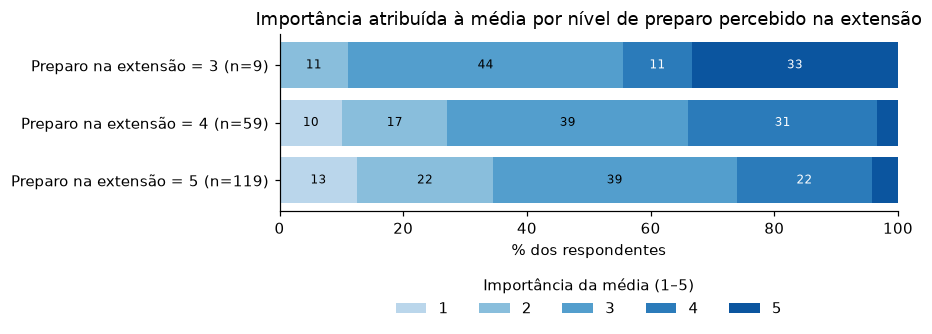

,coef (log-odds),p,OR
preparo_extensao,-0.1897,0.4479,0.8272
preparo_disciplinas,0.3723,0.0190,1.4510
objetivo_faculdade_Estágio,0.3085,0.3748,1.3613
objetivo_faculdade_Desempenho acadêmico,1.7056,0.0001,5.5045
objetivo_faculdade_Intercâmbio,3.2964,0.0000,27.0145
objetivo_faculdade_IC / Pesquisa,2.5486,0.0036,12.7898


In [28]:
print("Importância da média por nível de preparo na extensão")
display(df.groupby("preparo_extensao")["importancia_media"].agg(média="mean", mediana="median", n="size").round(2))
p5_cross = pd.crosstab(df["preparo_extensao"], df["importancia_media"])
p5_cross.index = [f"Preparo na extensão = {i}" for i in p5_cross.index]
plot_stacked_percent(p5_cross, "Importância atribuída à média por nível de preparo percebido na extensão",
                     "% dos respondentes", "Importância da média (1–5)", FIG_DIR / "08_importancia_por_preparo_extensao.png")

# Exploratory control for the current goal (complete cases)
d5 = df.dropna(subset=["objetivo_faculdade"])
X5 = pd.concat([d5[["preparo_extensao", "preparo_disciplinas"]].astype(float),
                pd.get_dummies(d5[["objetivo_faculdade"]], drop_first=True)], axis=1)
m5 = fit_ordinal_logit(d5["importancia_media"], X5)
pd.DataFrame({"coef (log-odds)": m5.params, "p": m5.pvalues, "OR": np.exp(m5.params)}).loc[X5.columns].round(4)

**(c) Resultado.**

- **Teste primário:** τ-b = −0,12 (IC 95%: −0,25 a 0,01), p = 0,069. Não é significativo nem antes nem depois de Holm. A importância média da nota cai de 3,67 (preparo na extensão = 3, n = 9) para 3,00 (nota 4) e 2,83 (nota 5); ver tabela acima.
- **Análise exploratória:**
  - a importância da média se associa positivamente ao preparo nas **disciplinas** (τ-b = 0,22, p < 0,001);
  - no modelo ordinal que controla o objetivo atual e o preparo nas disciplinas (n = 180), o coeficiente do preparo na extensão continua não significativo (OR = 0,83, p = 0,45), enquanto o das disciplinas é significativo (OR = 1,45, p = 0,019);
  - a associação negativa com o ganho líquido (τ-b = −0,23) vem do acoplamento com as disciplinas (cuidado 4), não da extensão.

**(d)** Figura 8, tabela `p5_importancia_vs_preparo.csv`.

**(e) Conclusão para o relatório.** Não há evidência de que quem percebe mais preparo na extensão dê menos importância à média ponderada (τ-b = −0,12; p = 0,07). A associação também não é significativa quando se controlam o objetivo atual e o preparo nas disciplinas. O que se associa à importância da média é a avaliação das disciplinas: quem as considera mais úteis também valoriza mais a nota (τ-b = 0,22; p < 0,001). Como o efeito teto reduz o poder deste teste, o resultado é ausência de evidência, e não evidência de ausência.

## 8. P6 — O objetivo atual na faculdade se associa à importância dada à média e ao preparo percebido nas disciplinas?

**(a) Pergunta e hipóteses.**

- **P6a:** $H_0$: a distribuição de `importancia_media` é igual entre os 5 objetivos; $H_1$: ao menos um objetivo difere.
- **P6b:** $H_0$: a distribuição de `preparo_disciplinas` é igual entre os 5 objetivos; $H_1$: ao menos um difere.

**(b) Teste e premissas.** Kruskal-Wallis + ε², Dunn com Holm e Welch como robustez; casos completos (n = 180). Cuidados: (i) "IC / Pesquisa" tem n = 6 — estimativas imprecisas, interpretadas só com o IC; (ii) **circularidade parcial**: a categoria "Desempenho acadêmico (manter/elevar a média ponderada)" contém a própria média na definição, de modo que sua alta importância funciona como *checagem de validade* do instrumento, não como descoberta. O achado substantivo está nas demais categorias (Intercâmbio, IC, Estágio).

In [29]:
d6 = df.dropna(subset=["objetivo_faculdade"]).copy()
d6["objetivo_faculdade"] = d6["objetivo_faculdade"].cat.remove_unused_categories()
p6 = compare_groups(d6, "objetivo_faculdade", [
    ("importancia_media", "Importância da média"),
    ("preparo_disciplinas", "Preparo nas disciplinas"),
    ("preparo_extensao", "Preparo na extensão (secundário)"),
])
for col, label, tag in [("importancia_media", "importância da média", "P6a"), ("preparo_disciplinas", "preparo nas disciplinas", "P6b")]:
    kw = kruskal_with_effect(d6, col, "objetivo_faculdade")
    register(tag, f"Kruskal-Wallis: {label} ~ objetivo", f'H({kw["df"]}) = {kw["H"]:.2f}', kw["p"], f'ε² = {kw["epsilon_sq"]:.3f}')
p6.to_csv(TAB_DIR / "p6_objetivo_kruskal.csv")
p6.round(5)

,n,H (gl),p Kruskal-Wallis,ε²,F de Welch (gl),p Welch,ω²,p Levene
Variável,,,,,,,,
Importância da média,180,48.55 (4),0.00000,0.27124,15.41 (4; 30.5),0.00000,0.24776,0.91452
Preparo nas disciplinas,180,16.50 (4),0.00241,0.09219,4.32 (4; 29.7),0.00709,0.07518,0.99258
Preparo na extensão (secundário),180,7.87 (4),0.09664,0.04394,1.76 (4; 28.9),0.16361,0.02160,0.05458


In [30]:
print("Dunn (Holm) — importância da média")
display(dunn_table(d6, "importancia_media", "objetivo_faculdade").round(5))
print("Dunn (Holm) — preparo nas disciplinas")
display(dunn_table(d6, "preparo_disciplinas", "objetivo_faculdade").round(5))

Dunn (Holm) — importância da média


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Grupo de extensão,Estágio,-0.73404,0.46292,1.00000
1,Grupo de extensão,Desempenho acadêmico,-4.27490,0.00002,0.00015
2,Grupo de extensão,Intercâmbio,-5.57152,0.00000,0.00000
3,Grupo de extensão,IC / Pesquisa,-3.05715,0.00223,0.01341
4,Estágio,Desempenho acadêmico,-3.41338,0.00064,0.00449
5,Estágio,Intercâmbio,-4.70708,0.00000,0.00002
6,Estágio,IC / Pesquisa,-2.68074,0.00735,0.03673
7,Desempenho acadêmico,Intercâmbio,-1.36057,0.17365,0.69460
8,Desempenho acadêmico,IC / Pesquisa,-0.75257,0.45171,1.00000
9,Intercâmbio,IC / Pesquisa,0.11097,0.91164,1.00000


Dunn (Holm) — preparo nas disciplinas


,Grupo 1,Grupo 2,z,p bruto,p Holm
0,Grupo de extensão,Estágio,0.88498,0.37616,1.00000
1,Grupo de extensão,Desempenho acadêmico,-3.35006,0.00081,0.00727
2,Grupo de extensão,Intercâmbio,-0.77532,0.43815,1.00000
3,Grupo de extensão,IC / Pesquisa,-1.13941,0.25453,1.00000
4,Estágio,Desempenho acadêmico,-3.79123,0.00015,0.00150
5,Estágio,Intercâmbio,-1.36012,0.17379,1.00000
6,Estágio,IC / Pesquisa,-1.49117,0.13592,0.95142
7,Desempenho acadêmico,Intercâmbio,1.95620,0.05044,0.40354
8,Desempenho acadêmico,IC / Pesquisa,0.59010,0.55513,1.00000
9,Intercâmbio,IC / Pesquisa,-0.64163,0.52111,1.00000


Importância da média por objetivo (IC bootstrap percentil e IC t)


,objetivo_faculdade,n,mean,median,ci_low,ci_high,IC t (inf),IC t (sup)
0,Grupo de extensão,77,2.52,3.0,2.32,2.71,2.32,2.72
1,Estágio,48,2.60,3.0,2.31,2.88,2.31,2.90
2,Desempenho acadêmico,27,3.48,3.0,3.22,3.78,3.18,3.78
3,Intercâmbio,22,3.91,4.0,3.45,4.32,3.46,4.36
4,IC / Pesquisa,6,3.83,4.0,3.33,4.33,3.04,4.62


Preparo nas disciplinas por objetivo (IC bootstrap percentil e IC t)


,objetivo_faculdade,n,mean,median,ci_low,ci_high,IC t (inf),IC t (sup)
0,Grupo de extensão,77,2.23,2.0,2.03,2.45,2.02,2.45
1,Estágio,48,2.06,2.0,1.83,2.29,1.81,2.31
2,Desempenho acadêmico,27,2.96,3.0,2.59,3.30,2.59,3.33
3,Intercâmbio,22,2.41,2.0,2.05,2.77,2.01,2.81
4,IC / Pesquisa,6,2.67,3.0,1.83,3.33,1.58,3.75


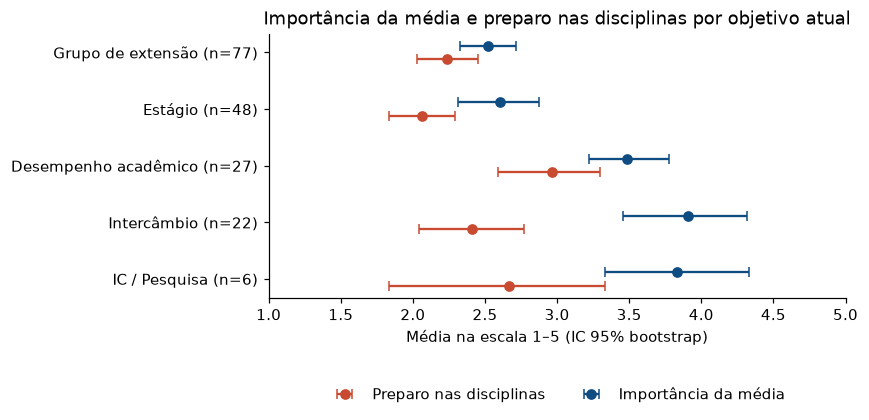

In [31]:
imp_by_goal = bootstrap_group_means(d6, "importancia_media", "objetivo_faculdade", n_boot=N_BOOT, seed=SEED)
disc_by_goal = bootstrap_group_means(d6, "preparo_disciplinas", "objetivo_faculdade", n_boot=N_BOOT, seed=SEED)
def add_t_interval(summary, data, value, group):
    """Adds a t-based 95% CI next to the percentile bootstrap (the bootstrap under-covers when n < ~10)."""
    rows = []
    for level, sub in data.groupby(group, observed=True):
        v = sub[value].to_numpy(dtype=float)
        half = stats.t.ppf(0.975, v.size - 1) * v.std(ddof=1) / np.sqrt(v.size)
        rows.append({group: level, "IC t (inf)": v.mean() - half, "IC t (sup)": v.mean() + half})
    return summary.merge(pd.DataFrame(rows), on=group)


print("Importância da média por objetivo (IC bootstrap percentil e IC t)")
display(add_t_interval(imp_by_goal, d6, "importancia_media", "objetivo_faculdade").round(2))
print("Preparo nas disciplinas por objetivo (IC bootstrap percentil e IC t)")
display(add_t_interval(disc_by_goal, d6, "preparo_disciplinas", "objetivo_faculdade").round(2))
plot_group_means(imp_by_goal, disc_by_goal, "objetivo_faculdade",
                 "Importância da média e preparo nas disciplinas por objetivo atual",
                 FIG_DIR / "09_importancia_e_disciplinas_por_objetivo.png", order=GOAL_ORDER,
                 labels=("Importância da média", "Preparo nas disciplinas"))

**(c) Resultado.**

- **Importância da média (P6a):** H(4) = 48,55, p = 7,2 × 10⁻¹⁰, ε² = 0,27 (efeito grande). Formam-se dois blocos:
  - {Grupo de extensão 2,52; Estágio 2,60};
  - {Desempenho acadêmico 3,48; IC / Pesquisa 3,83; Intercâmbio 3,91}.

  Todas as comparações entre os blocos são significativas no Dunn com Holm (p ≤ 0,037), e nenhuma comparação dentro de um mesmo bloco é.
- **Preparo nas disciplinas (P6b):** H(4) = 16,50, p = 0,0024, ε² = 0,09.
  - "Desempenho acadêmico" (2,96) supera Estágio (2,06) e Grupo de extensão (2,23), com p de Holm < 0,01.
  - Não difere significativamente de Intercâmbio (2,41; p = 0,40) nem de IC / Pesquisa (2,67; p = 1,00).
- **Robustez:** a ANOVA de Welch concorda nos dois casos, e o teste de Levene não indica variâncias diferentes (p ≥ 0,91).
- **IC / Pesquisa** tem n = 6: o IC por bootstrap percentil (3,3 a 4,3) subestima a incerteza nesse tamanho; o IC t (3,0 a 4,6) é a referência mais honesta.

**(d)** Figura 9, tabela `p6_objetivo_kruskal.csv`.

**(e) Conclusão para o relatório.** O objetivo atual é o fator mais fortemente associado à importância dada à média (ε² = 0,27). Quem mira intercâmbio (média 3,9) ou iniciação científica (3,8) não difere significativamente de quem declara o desempenho acadêmico como objetivo (3,5), e valoriza a média bem mais do que quem foca no grupo de extensão (2,5) ou no estágio (2,6). Isso é coerente com processos seletivos de intercâmbio e IC que usam a média como critério. Quem prioriza o desempenho acadêmico também avalia melhor as disciplinas do que quem foca no estágio ou no grupo (3,0 contra 2,1–2,2).

## 9. P7 — Modelo: é possível prever o preparo na extensão e o ganho líquido a partir da categoria, do tempo e das horas?

Seguindo o encadeamento do guia, o modelo usa as variáveis da própria pergunta e é avaliado (i) explicativamente — razão de verossimilhança, razões de chances e IC — e (ii) preditivamente, por **validação cruzada** (5 *folds* × 20 repetições), comparando com um modelo nulo. Avaliar só dentro da amostra superestimaria o poder preditivo.

**P7a — Preparo na extensão.** Por causa do teto (3 níveis usados, 64% em 5), o desfecho principal é binário, $Y_i = 1$ se `preparo_extensao` = 5, com regressão logística:
$$\text{logit}\,P(Y_i = 1) = \beta_0 + \beta_1\,\text{horas}_i + \beta_2\,\text{tempo}_i + \boldsymbol{\gamma}^\top \text{categoria}_i .$$
$H_0$ (para cada bloco): o bloco não melhora o ajuste (LR em modelos aninhados). Robustez: modelo logístico ordinal (*proportional odds*) com os 3 níveis.

**P7b — Ganho líquido.** MQO de `delta_preparo` com os mesmos preditores, erros-padrão robustos HC3 e IC bootstrap dos coeficientes; diagnóstico de resíduos (Shapiro-Wilk, Breusch-Pagan, VIF).

In [32]:
logit_models = {
    "Nulo": smf.logit("preparo_ext_maximo ~ 1", df).fit(disp=False),
    "Horas": smf.logit("preparo_ext_maximo ~ horas_ord", df).fit(disp=False),
    "Horas + tempo": smf.logit("preparo_ext_maximo ~ horas_ord + tempo_ord", df).fit(disp=False),
    "Horas + tempo + categoria": smf.logit("preparo_ext_maximo ~ horas_ord + tempo_ord + C(categoria_extensao)", df).fit(disp=False),
}
steps = [("Horas", "Nulo"), ("Horas + tempo", "Horas"), ("Horas + tempo + categoria", "Horas + tempo")]
lr_rows = []
for big, small in steps:
    t = likelihood_ratio_test(logit_models[big].llf, logit_models[small].llf, int(logit_models[big].df_model - logit_models[small].df_model))
    lr_rows.append({"Comparação": f"{big} vs. {small}", "LR": t["LR"], "gl": t["df"], "p": t["p"],
                    "AIC": logit_models[big].aic, "R² de McFadden": logit_models[big].prsquared})
p7_lr = pd.DataFrame(lr_rows).set_index("Comparação")
register("P7a (modelo)", "LR: horas no logit de P(nota 5)", f'LR(1) = {p7_lr.iloc[0]["LR"]:.2f}', p7_lr.iloc[0]["p"],
         f'OR = {np.exp(logit_models["Horas"].params["horas_ord"]):.2f}/faixa')
display(p7_lr.round(4))
horas_only = logit_models["Horas"]
ci_h = np.exp(horas_only.conf_int().loc["horas_ord"])
print(f'Modelo só com horas: OR = {np.exp(horas_only.params["horas_ord"]):.2f} por faixa (IC 95%: {ci_h.iloc[0]:.2f} a {ci_h.iloc[1]:.2f})')

,LR,gl,p,AIC,R² de McFadden
Comparação,,,,,
Horas vs. Nulo,24.0298,1,0.0000,225.1204,0.0980
Horas + tempo vs. Horas,0.1755,1,0.6753,226.9449,0.0987
Horas + tempo + categoria vs. Horas + tempo,0.6862,3,0.8764,232.2587,0.1015


Modelo só com horas: OR = 1.93 por faixa (IC 95%: 1.45 a 2.55)


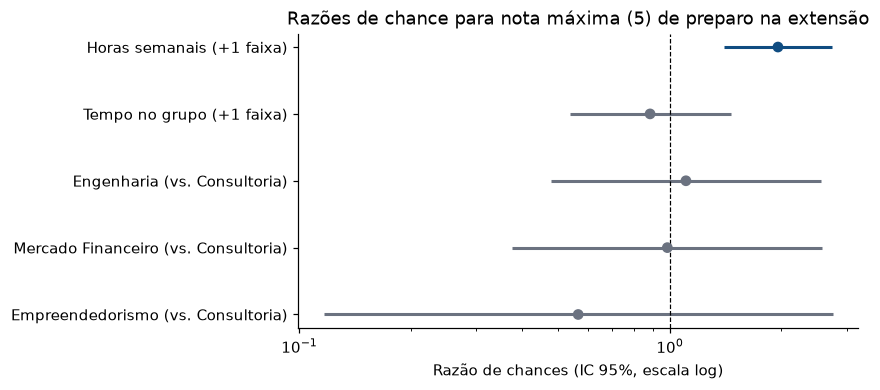

,estimate,ci_low,ci_high,p
Horas semanais (+1 faixa),1.958,1.402,2.735,0.000
Tempo no grupo (+1 faixa),0.885,0.537,1.458,0.631
Engenharia (vs. Consultoria),1.106,0.477,2.560,0.815
Mercado Financeiro (vs. Consultoria),0.985,0.376,2.582,0.975
Empreendedorismo (vs. Consultoria),0.566,0.117,2.749,0.480


In [33]:
full_logit = logit_models["Horas + tempo + categoria"]
LABELS_P7 = {
    "horas_ord": "Horas semanais (+1 faixa)",
    "tempo_ord": "Tempo no grupo (+1 faixa)",
    "C(categoria_extensao)[T.Engenharia]": "Engenharia (vs. Consultoria)",
    "C(categoria_extensao)[T.Mercado Financeiro]": "Mercado Financeiro (vs. Consultoria)",
    "C(categoria_extensao)[T.Empreendedorismo]": "Empreendedorismo (vs. Consultoria)",
}
ci = full_logit.conf_int()
p7_or = pd.DataFrame({"estimate": np.exp(full_logit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                      "p": full_logit.pvalues}).loc[list(LABELS_P7)].rename(index=LABELS_P7)
p7_or.to_csv(TAB_DIR / "p7_logit_razoes_de_chance.csv")
plot_coefficients(p7_or, "Razões de chance para nota máxima (5) de preparo na extensão",
                  "Razão de chances (IC 95%, escala log)", FIG_DIR / "10_p7_razoes_de_chance.png")
p7_or.round(3)

In [34]:
cv_rows = []
for name, rhs in [("Horas", "horas_ord"), ("Horas + tempo + categoria", "horas_ord + tempo_ord + C(categoria_extensao)")]:
    aucs, briers, briers_null, not_converged = [], [], [], 0
    for train_idx, test_idx in repeated_kfold_indices(df["preparo_ext_maximo"], n_splits=5, n_repeats=20, seed=SEED):
        train, test = df.iloc[train_idx], df.iloc[test_idx]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # quasi-separation is counted below instead of printed
            fit = smf.logit(f"preparo_ext_maximo ~ {rhs}", train).fit(disp=False, maxiter=200)
        not_converged += not fit.mle_retvals["converged"]
        prob = fit.predict(test)
        aucs.append(roc_auc(test["preparo_ext_maximo"], prob))
        briers.append(np.mean((test["preparo_ext_maximo"] - prob) ** 2))
        briers_null.append(np.mean((test["preparo_ext_maximo"] - train["preparo_ext_maximo"].mean()) ** 2))
    cv_rows.append({"Modelo": name, "AUC (CV)": np.mean(aucs), "DP AUC": np.std(aucs), "Brier (CV)": np.mean(briers),
                    "Brier do nulo (CV)": np.mean(briers_null), "AUC na amostra": roc_auc(df["preparo_ext_maximo"], logit_models[name].predict(df)),
                    "Ajustes sem convergência": f"{not_converged}/100"})
p7_cv = pd.DataFrame(cv_rows).set_index("Modelo")
p7_cv.to_csv(TAB_DIR / "p7_validacao_cruzada_logit.csv")
p7_cv.round(3)

,AUC (CV),DP AUC,Brier (CV),Brier do nulo (CV),AUC na amostra,Ajustes sem convergência
Modelo,,,,,,
Horas,0.708,0.078,0.206,0.231,0.707,0/100
Horas + tempo + categoria,0.687,0.079,0.216,0.231,0.715,1/100


In [35]:
# Robustness: proportional-odds model with the 3 observed levels
X_p7 = pd.concat([df[["horas_ord", "tempo_ord"]].astype(float), pd.get_dummies(df[["categoria_extensao"]], drop_first=True)], axis=1)
m_p7_ord = fit_ordinal_logit(df["preparo_extensao"], X_p7)
pd.DataFrame({"coef (log-odds)": m_p7_ord.params, "p": m_p7_ord.pvalues, "OR": np.exp(m_p7_ord.params)}).loc[X_p7.columns].round(4)

,coef (log-odds),p,OR
horas_ord,0.7105,0.0000,2.0350
tempo_ord,-0.1379,0.5815,0.8712
categoria_extensao_Engenharia,0.1529,0.7181,1.1652
categoria_extensao_Mercado Financeiro,0.0490,0.9191,1.0502
categoria_extensao_Empreendedorismo,-0.2407,0.7420,0.7861


**P7b — Ganho líquido (MQO).**

In [36]:
FORMULA_P7B = "delta_preparo ~ horas_ord + tempo_ord + C(categoria_extensao)"
ols_delta = smf.ols(FORMULA_P7B, df).fit(cov_type="HC3")

rng = np.random.default_rng(SEED)
boot_coefs = []
for _ in range(N_BOOT):
    sample = df.iloc[rng.integers(0, len(df), len(df))]
    if sample["categoria_extensao"].nunique() < len(CATEGORY_ORDER):
        continue  # a resample without one category cannot estimate its coefficient
    boot_coefs.append(smf.ols(FORMULA_P7B, sample).fit().params)
boot_coefs = pd.DataFrame(boot_coefs)

p7b = pd.DataFrame({
    "coef": ols_delta.params, "EP robusto (HC3)": ols_delta.bse, "p (HC3)": ols_delta.pvalues,
    "IC 95% bootstrap": [f"[{lo:.2f}; {hi:.2f}]" for lo, hi in zip(boot_coefs.quantile(0.025), boot_coefs.quantile(0.975))],
})
print(f"R² = {ols_delta.rsquared:.3f} | R² ajustado = {ols_delta.rsquared_adj:.3f} | F (HC3) p = {ols_delta.f_pvalue:.2e} | "
      f"reamostragens bootstrap válidas = {len(boot_coefs)}")
p7b.to_csv(TAB_DIR / "p7_mqo_ganho_liquido.csv")
p7b.round(4)

R² = 0.200 | R² ajustado = 0.178 | F (HC3) p = 1.16e-07 | reamostragens bootstrap válidas = 4999


,coef,EP robusto (HC3),p (HC3),IC 95% bootstrap
Intercept,1.5842,0.3866,0.0000,[0.86; 2.33]
C(categoria_extensao)[T.Engenharia],-0.6295,0.2257,0.0053,[-1.05; -0.19]
C(categoria_extensao)[T.Mercado Financeiro],-0.1198,0.2082,0.5651,[-0.52; 0.28]
C(categoria_extensao)[T.Empreendedorismo],0.1056,0.3176,0.7396,[-0.50; 0.70]
horas_ord,0.3153,0.0810,0.0001,[0.16; 0.47]
tempo_ord,-0.0488,0.1289,0.7049,[-0.29; 0.20]


In [37]:
residuals = ols_delta.resid
exog = ols_delta.model.exog
diagnostics = pd.Series({
    "Shapiro-Wilk dos resíduos: p": stats.shapiro(residuals).pvalue,
    "Breusch-Pagan (heterocedasticidade): p": het_breuschpagan(residuals, exog)[1],
    "VIF máximo": max(variance_inflation_factor(exog, i) for i in range(1, exog.shape[1])),
}).round(4)
display(diagnostics.to_frame("valor"))

r2_cv = []
for train_idx, test_idx in repeated_kfold_indices(np.zeros(len(df)), n_splits=5, n_repeats=20, stratified=False, seed=SEED):
    train, test = df.iloc[train_idx], df.iloc[test_idx]
    pred = smf.ols(FORMULA_P7B, train).fit().predict(test)
    r2_cv.append(1 - np.sum((test["delta_preparo"] - pred) ** 2) / np.sum((test["delta_preparo"] - train["delta_preparo"].mean()) ** 2))
print(f"R² fora da amostra (CV 5×20): {np.mean(r2_cv):.3f} ± {np.std(r2_cv):.3f}")

print("\nDecomposição: mesmos preditores para cada componente do ganho (coeficientes MQO)")
decomp = pd.DataFrame({y: smf.ols(f"{y} ~ horas_ord + tempo_ord + C(categoria_extensao)", df).fit(cov_type="HC3").params
                       for y in ["preparo_extensao", "preparo_disciplinas", "delta_preparo"]})
decomp.round(3)

,valor
Shapiro-Wilk dos resíduos: p,0.3487
Breusch-Pagan (heterocedasticidade): p,0.0230
VIF máximo,1.3709


R² fora da amostra (CV 5×20): 0.154 ± 0.108

Decomposição: mesmos preditores para cada componente do ganho (coeficientes MQO)


,preparo_extensao,preparo_disciplinas,delta_preparo
Intercept,4.108,2.523,1.584
C(categoria_extensao)[T.Engenharia],0.037,0.666,-0.630
C(categoria_extensao)[T.Mercado Financeiro],-0.005,0.115,-0.120
C(categoria_extensao)[T.Empreendedorismo],-0.040,-0.146,0.106
horas_ord,0.181,-0.134,0.315
tempo_ord,-0.035,0.014,-0.049


**(c) Resultado.**

**P7a (nota máxima de preparo na extensão):**

- **Horas** são o único bloco que melhora o ajuste: LR = 24,0 (gl 1), p = 9,5 × 10⁻⁷. No modelo só com horas, OR = 1,93 por faixa (IC 95%: 1,45 a 2,55); no modelo completo, ajustado por tempo e categoria, OR = 1,96 (1,40 a 2,74).
- **Tempo** (p = 0,68) e **categoria** (p = 0,88) não melhoram o ajuste e pioram o AIC (de 225,1 para 232,3).
- **Fora da amostra:** AUC = 0,71 no modelo só com horas, contra 0,69 no modelo completo, que sobreajusta (1 dos seus 100 ajustes não convergiu, ligado à categoria Empreendedorismo, com n = 8). Brier de 0,206 contra 0,231 do modelo nulo.
- **Robustez:** o modelo ordinal com os 3 níveis leva à mesma conclusão (OR das horas = 2,03, p < 0,001; demais termos com p > 0,5).

**P7b (ganho líquido):**

- **Ajuste:** R² = 0,20 (ajustado 0,18; 0,15 ± 0,11 na validação cruzada).
- **Coeficientes:**
  - horas: +0,32 por faixa (bootstrap: 0,16 a 0,47);
  - Engenharia: −0,63 em relação a Consultoria (−1,05 a −0,19);
  - tempo e demais categorias: não significativos.
- **Diagnóstico:**
  - resíduos compatíveis com normalidade (Shapiro p = 0,35);
  - heterocedasticidade presente (Breusch-Pagan p = 0,023), o que justifica os erros-padrão HC3 e o bootstrap;
  - VIF ≤ 1,4.
- **Decomposição (mesmos preditores para cada componente):**
  - o coeficiente das horas aparece nas duas componentes (+0,18 na extensão e −0,13 nas disciplinas; esta última não é significativa dentro de cada categoria);
  - o de Engenharia aparece só nas disciplinas (+0,67).

**(d)** Figura 10, tabelas `p7_*.csv`.

**(e) Conclusão para o relatório.** Dá para prever o preparo percebido na extensão, mas só de forma modesta. A dedicação semanal é o único preditor relevante: cada faixa de horas a mais praticamente dobra a chance de nota máxima (OR = 1,93; IC 95%: 1,45 a 2,55), com poder discriminante moderado fora da amostra (AUC = 0,71). Categoria do grupo e tempo de permanência não acrescentam informação. O modelo do ganho líquido explica de 15% a 20% da variância, com mais horas (+0,32 ponto por faixa) e grupo técnico (−0,63 ponto). Pela decomposição, esta diferença acompanha a avaliação das disciplinas, não a da extensão. São associações em uma amostra de conveniência, que não servem para prever casos individuais.

## 10. P8 — Modelo: curso, categoria do grupo e objetivo estimam a importância dada à média?

**Modelo.** Regressão logística ordinal (*proportional odds*) de `importancia_media` (5 níveis) com objetivo atual, categoria do grupo e grande área do curso (n = 180, casos completos):
$$\text{logit}\,P(Y_i \le j) = \alpha_j - (\boldsymbol{\beta}^\top \text{objetivo}_i + \boldsymbol{\gamma}^\top \text{categoria}_i + \boldsymbol{\delta}^\top \text{área}_i), \quad j = 1,\dots,4.$$

**Hipóteses.** Para cada bloco $B$: $H_0$: todos os coeficientes de $B$ são nulos, dado o restante; $H_1$: algum é diferente de zero (LR retirando um bloco por vez).

**Premissas.** (i) Chances proporcionais — checadas comparando os coeficientes de logísticas binárias em dois cortes (≥ 3 e ≥ 4); (ii) independência ✔; (iii) ausência de separação — monitorada pelos erros-padrão. Avaliação preditiva por validação cruzada estratificada (5 × 10): erro absoluto médio (MAE) da previsão arredondada, acurácia e ρ entre previsto e observado, comparados com a previsão constante (mediana/moda do treino). Sensibilidade: incluir a média ponderada (escore ordinal das faixas, como recomenda a regra 3) e retirar "Empreendedorismo" (n = 8).

In [38]:
d8 = df.dropna(subset=["objetivo_faculdade"]).copy()
d8["objetivo_faculdade"] = d8["objetivo_faculdade"].cat.remove_unused_categories()
BLOCKS = {"Objetivo atual": "objetivo_faculdade", "Categoria do grupo": "categoria_extensao", "Grande área": "grande_area_curso"}


def design(data, cols):
    return pd.get_dummies(data[cols], drop_first=True)


X8 = design(d8, list(BLOCKS.values()))
m8 = fit_ordinal_logit(d8["importancia_media"], X8)
ll0 = ordinal_null_loglik(d8["importancia_media"])
global_lr = likelihood_ratio_test(m8.llf, ll0, X8.shape[1])
print(f'Modelo completo: LR global = {global_lr["LR"]:.2f} (gl = {global_lr["df"]}), p = {global_lr["p"]:.1e}; '
      f'R² de McFadden = {1 - m8.llf / ll0:.3f}')

rows = []
for block_name, col in BLOCKS.items():
    reduced = fit_ordinal_logit(d8["importancia_media"], design(d8, [c for c in BLOCKS.values() if c != col]))
    t = likelihood_ratio_test(m8.llf, reduced.llf, X8.shape[1] - (len(reduced.params) - 4))
    rows.append({"Bloco retirado": block_name, "LR": t["LR"], "gl": t["df"], "p": t["p"]})
p8_blocks = pd.DataFrame(rows).set_index("Bloco retirado")
register("P8 (modelo)", "LR: bloco objetivo no logit ordinal da importância", f'LR({int(p8_blocks.loc["Objetivo atual", "gl"])}) = {p8_blocks.loc["Objetivo atual", "LR"]:.2f}',
         p8_blocks.loc["Objetivo atual", "p"], f'McFadden R² = {1 - m8.llf / ll0:.2f}')
ols8 = smf.ols("importancia_media ~ C(objetivo_faculdade) + C(categoria_extensao) + C(grande_area_curso)", d8).fit()
print(f"Referência: R² do MQO com os mesmos preditores = {ols8.rsquared:.3f} (ajustado {ols8.rsquared_adj:.3f}), n = {int(ols8.nobs)}")
p8_blocks.to_csv(TAB_DIR / "p8_lr_por_bloco.csv")
p8_blocks.round(5)

Modelo completo: LR global = 72.49 (gl = 11), p = 4.1e-11; R² de McFadden = 0.141


Referência: R² do MQO com os mesmos preditores = 0.323 (ajustado 0.278), n = 180


,LR,gl,p
Bloco retirado,,,
Objetivo atual,65.80760,4,0.00000
Categoria do grupo,10.20616,3,0.01689
Grande área,3.50018,4,0.47785


Referências: objetivo = Grupo de extensão; categoria = Consultoria & Negócios; área = Civil & Ambiental


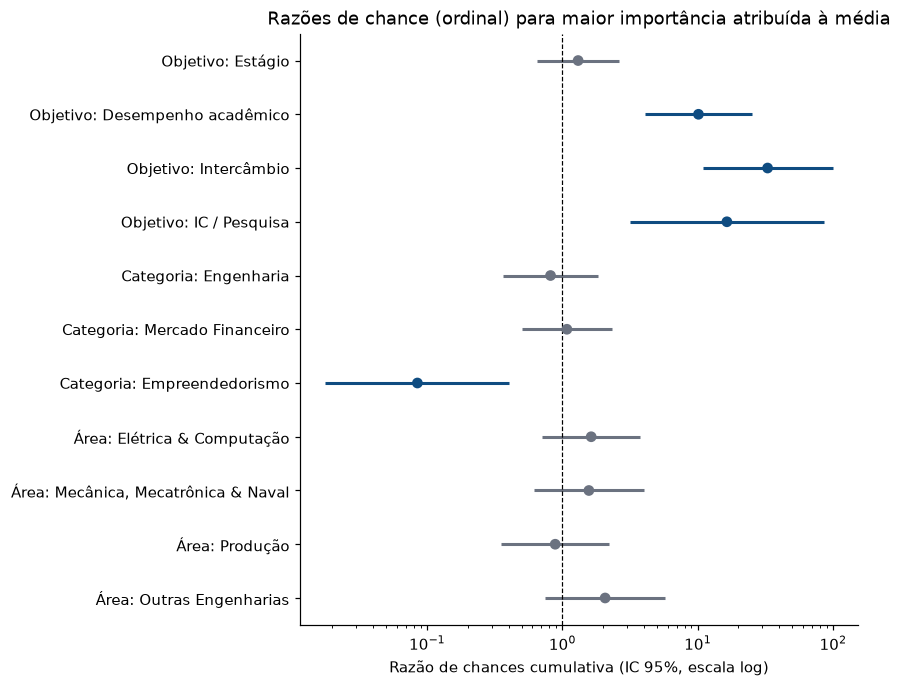

,estimate,ci_low,ci_high,p
Objetivo: Estágio,1.308,0.652,2.622,0.450
Objetivo: Desempenho acadêmico,10.134,4.088,25.122,0.000
Objetivo: Intercâmbio,32.864,10.865,99.404,0.000
Objetivo: IC / Pesquisa,16.444,3.151,85.831,0.001
Categoria: Engenharia,0.818,0.363,1.841,0.627
Categoria: Mercado Financeiro,1.080,0.501,2.332,0.844
Categoria: Empreendedorismo,0.085,0.018,0.406,0.002
Área: Elétrica & Computação,1.633,0.711,3.750,0.247
"Área: Mecânica, Mecatrônica & Naval",1.571,0.613,4.026,0.347
Área: Produção,0.885,0.354,2.215,0.795


In [39]:
def clean_label(name):
    for prefix, nice in [("objetivo_faculdade_", "Objetivo: "), ("categoria_extensao_", "Categoria: "), ("grande_area_curso_", "Área: ")]:
        if name.startswith(prefix):
            return nice + name[len(prefix):]
    return name


coef = m8.params.loc[X8.columns]
ci8 = m8.conf_int().loc[X8.columns]
p8_or = pd.DataFrame({"estimate": np.exp(coef), "ci_low": np.exp(ci8[0]), "ci_high": np.exp(ci8[1]), "p": m8.pvalues.loc[X8.columns]})
p8_or.index = [clean_label(c) for c in p8_or.index]
p8_or.to_csv(TAB_DIR / "p8_ordinal_razoes_de_chance.csv")
print("Referências: objetivo = Grupo de extensão; categoria = Consultoria & Negócios; área = Civil & Ambiental")
plot_coefficients(p8_or, "Razões de chance (ordinal) para maior importância atribuída à média",
                  "Razão de chances cumulativa (IC 95%, escala log)", FIG_DIR / "11_p8_razoes_de_chance.png")
p8_or.round(3)

In [40]:
# Proportional-odds check: binary logits at two cut-points, objective coefficients only
po_check = pd.DataFrame(index=GOAL_ORDER[1:])
for cut in [3, 4]:
    y_bin = (d8["importancia_media"] >= cut).astype(int)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # separation is reported explicitly below
        fit = smf.logit("y ~ C(objetivo_faculdade) + C(categoria_extensao) + C(grande_area_curso)",
                        d8.assign(y=y_bin)).fit(disp=False, maxiter=200)
    params = fit.params.filter(like="objetivo_faculdade")
    params.index = [i.split("T.")[-1].rstrip("]") for i in params.index]
    errors = fit.bse.filter(like="objetivo_faculdade")
    errors.index = params.index
    po_check[f"≥ {cut}: coef"] = params
    po_check[f"≥ {cut}: EP"] = errors
ordinal_coef = m8.params.filter(like="objetivo_faculdade")
ordinal_coef.index = [i.replace("objetivo_faculdade_", "") for i in ordinal_coef.index]
po_check["Ordinal: coef"] = ordinal_coef
print("Coeficientes (log-odds) do objetivo em cada corte — devem ser parecidos se a premissa de chances proporcionais vale.")
print("Casos de 'IC / Pesquisa' abaixo de 3:", int((d8.loc[d8["objetivo_faculdade"] == "IC / Pesquisa", "importancia_media"] < 3).sum()),
      "→ separação completa no corte ≥ 3 (coeficiente e EP desse corte não são interpretáveis).")
po_check.round(2)

Coeficientes (log-odds) do objetivo em cada corte — devem ser parecidos se a premissa de chances proporcionais vale.
Casos de 'IC / Pesquisa' abaixo de 3: 0 → separação completa no corte ≥ 3 (coeficiente e EP desse corte não são interpretáveis).


,≥ 3: coef,≥ 3: EP,≥ 4: coef,≥ 4: EP,Ordinal: coef
Estágio,0.49,0.40,0.58,0.54,0.27
Desempenho acadêmico,3.14,0.90,2.11,0.56,2.32
Intercâmbio,2.64,0.90,4.00,0.75,3.49
IC / Pesquisa,24.68,99718.97,2.96,1.02,2.80


In [41]:
metrics = {"MAE": [], "MAE do nulo (mediana)": [], "Acurácia": [], "Acurácia do nulo (moda)": [], "ρ previsto × observado": []}
for train_idx, test_idx in repeated_kfold_indices(d8["importancia_media"], n_splits=5, n_repeats=10, seed=SEED):
    X_train, X_test = X8.iloc[train_idx], X8.iloc[test_idx]
    keep = X_train.columns[X_train.sum() > 0]  # drop dummies absent from the training fold
    y_train, y_test = d8["importancia_media"].iloc[train_idx], d8["importancia_media"].iloc[test_idx]
    fit = fit_ordinal_logit(y_train, X_train[keep])
    probs = fit.model.predict(fit.params, exog=X_test[keep].astype(float).to_numpy())
    levels = np.sort(y_train.unique())
    expected = probs @ levels
    metrics["MAE"].append(np.mean(np.abs(y_test - np.round(expected))))
    metrics["MAE do nulo (mediana)"].append(np.mean(np.abs(y_test - np.median(y_train))))
    metrics["Acurácia"].append(np.mean(levels[probs.argmax(axis=1)] == y_test))
    metrics["Acurácia do nulo (moda)"].append(np.mean(y_test == y_train.mode().iloc[0]))
    metrics["ρ previsto × observado"].append(stats.spearmanr(expected, y_test).statistic)
p8_cv = pd.DataFrame(metrics).agg(["mean", "std"]).T.rename(columns={"mean": "média (CV)", "std": "DP"})
p8_cv.to_csv(TAB_DIR / "p8_validacao_cruzada.csv")
p8_cv.round(3)

,média (CV),DP
MAE,0.749,0.080
MAE do nulo (mediana),0.766,0.020
Acurácia,0.449,0.067
Acurácia do nulo (moda),0.400,0.009
ρ previsto × observado,0.408,0.105


In [42]:
# Sensitivity 1: add the weighted average (ordinal score of the bands; complete cases only)
d8b = d8.dropna(subset=["media_ponderada"]).copy()
X8b = design(d8b, list(BLOCKS.values()))
X8b["media_ponderada_escore"] = d8b["media_ponderada"].cat.codes + 1
m8b = fit_ordinal_logit(d8b["importancia_media"], X8b)
# Sensitivity 2: drop the 8 respondents of Empreendedorismo
d8c = d8[d8["categoria_extensao"] != "Empreendedorismo"].copy()
d8c["categoria_extensao"] = d8c["categoria_extensao"].cat.remove_unused_categories()
m8c = fit_ordinal_logit(d8c["importancia_media"], design(d8c, list(BLOCKS.values())))

objective_cols = [c for c in X8.columns if c.startswith("objetivo_faculdade_")]
sensitivity = pd.DataFrame({
    "Modelo principal": m8.params.loc[objective_cols],
    "+ média ponderada (escore)": m8b.params.loc[objective_cols],
    "Sem Empreendedorismo": m8c.params.loc[objective_cols],
})
sensitivity.index = [clean_label(c) for c in sensitivity.index]
print(f'Média ponderada (escore), n = {len(d8b)}: coef = {m8b.params["media_ponderada_escore"]:.3f} '
      f'(OR = {np.exp(m8b.params["media_ponderada_escore"]):.2f}), p = {m8b.pvalues["media_ponderada_escore"]:.4f}')
print("Coeficientes (log-odds) do objetivo nas análises de sensibilidade:")
sensitivity.round(2)

Média ponderada (escore), n = 178: coef = 0.364 (OR = 1.44), p = 0.0128
Coeficientes (log-odds) do objetivo nas análises de sensibilidade:


,Modelo principal,+ média ponderada (escore),Sem Empreendedorismo
Objetivo: Estágio,0.27,0.35,0.41
Objetivo: Desempenho acadêmico,2.32,2.53,2.21
Objetivo: Intercâmbio,3.49,3.47,3.61
Objetivo: IC / Pesquisa,2.80,2.70,2.89


**(c) Resultado.**

- **Modelo global:** LR = 72,5 (gl 11), p = 4 × 10⁻¹¹. R² de McFadden = 0,14; como referência, o R² do MQO com os mesmos preditores é 0,32.
- **Por bloco:**
  - objetivo: LR = 65,8 (gl 4), p < 10⁻¹²;
  - categoria: LR = 10,2 (gl 3), p = 0,017, efeito inteiramente devido a Empreendedorismo (OR = 0,09 com n = 8; Engenharia e Mercado Financeiro ficam com OR ≈ 1);
  - área: LR = 3,5 (gl 4), p = 0,48.
- **Razões de chance cumulativas** em relação a "Grupo de extensão":
  - Intercâmbio: 33 (IC 95%: 11 a 99);
  - IC / Pesquisa: 16 (3 a 86);
  - Desempenho acadêmico: 10 (4 a 25);
  - Estágio: 1,3 (0,7 a 2,6).
- **Premissa de chances proporcionais (checagem informal):** os coeficientes do objetivo nos cortes ≥ 3 e ≥ 4 têm o mesmo sinal e magnitudes próximas. A maior diferença é a de Intercâmbio (2,64 contra 4,00), cerca de 1,2 erro-padrão se as duas estimativas fossem independentes. Como elas são positivamente correlacionadas, essa checagem é leniente; um teste de Brant formal não está disponível no statsmodels. IC / Pesquisa no corte ≥ 3 tem separação completa (nenhum dos 6 casos abaixo de 3).
- **Sensibilidade:** acrescentando a média ponderada (n = 178; OR = 1,44 por faixa, p = 0,013) ou retirando Empreendedorismo, os coeficientes do objetivo mudam menos de 0,25 log-odds.
- **Validação cruzada:** MAE de 0,75 contra 0,77 do nulo; acurácia de 45% contra 40%; ρ(previsto, observado) = 0,41.

**(d)** Figura 11, tabelas `p8_*.csv`.

**(e) Conclusão para o relatório.** A importância atribuída à média está fortemente associada ao objetivo atual na graduação. Quem mira intercâmbio tem uma chance cerca de 33 vezes maior (IC 95%: 11 a 99) de atribuir mais importância à média do que quem foca no grupo de extensão. A área do curso não acrescenta informação, e a categoria do grupo também não, exceto Empreendedorismo, que tem só n = 8. O modelo como um todo explica uma parcela modesta (R² de McFadden = 0,14) e é fraco para prever casos individuais: acerta 45% das notas exatas, contra 40% de um palpite constante (ρ = 0,41), porque a maioria dos alunos se concentra nos objetivos "grupo" e "estágio", que não se distinguem entre si.

## 11. Correção para comparações múltiplas

Família = os testes primários registrados em cada bloco (a). Holm controla a probabilidade de **pelo menos um** falso positivo na família (FWER) sem supor independência entre os testes; Benjamini-Hochberg (FDR) aparece como referência menos conservadora.

In [43]:
family = pd.DataFrame(primary_tests)
family["p Holm"] = adjust_pvalues(family["p"].to_numpy(), method="holm")
family["p BH (FDR)"] = adjust_pvalues(family["p"].to_numpy(), method="bh")
family["Rejeita H0 (Holm, α = 0,05)"] = np.where(family["p Holm"] < ALPHA, "Sim", "Não")
family.to_csv(TAB_DIR / "familia_testes_primarios_holm.csv", index=False)
family_display = family.copy()
for col in ["p", "p Holm", "p BH (FDR)"]:
    family_display[col] = family_display[col].map(lambda v: f"{v:.2e}")
family_display

,Pergunta,Teste primário,Estatística,p,Tamanho de efeito,p Holm,p BH (FDR),"Rejeita H0 (Holm, α = 0,05)"
0,P1,Wilcoxon pareado,W = 18,6.96e-31,r_rb = 0.998,7.66e-30,7.66e-30,Sim
1,P2,Kruskal-Wallis: ganho líquido ~ grande área,H(4) = 9.66,4.65e-02,ε² = 0.052,1.86e-01,6.40e-02,Não
2,P3 (ganho líquido),Kruskal-Wallis: ganho líquido ~ categoria,H(3) = 22.48,5.19e-05,ε² = 0.121,3.11e-04,9.51e-05,Sim
3,P3 (preparo na extensão),Kruskal-Wallis: preparo na extensão ~ categoria,H(3) = 5.64,1.31e-01,ε² = 0.030,2.61e-01,1.44e-01,Não
4,P4a (horas),τ-b de Kendall: horas semanais (faixa) × prepa...,τ-b = 0.324,5.72e-07,τ-b = 0.32,4.57e-06,1.57e-06,Sim
5,P4b (tempo de grupo),τ-b de Kendall: tempo no grupo (faixa) × prepa...,τ-b = 0.072,2.92e-01,τ-b = 0.07,2.92e-01,2.92e-01,Não
6,P5,τ-b de Kendall: preparo na extensão × importân...,τ-b = -0.120,6.86e-02,τ-b = -0.12,2.06e-01,8.39e-02,Não
7,P6a,Kruskal-Wallis: importância da média ~ objetivo,H(4) = 48.55,7.24e-10,ε² = 0.271,6.52e-09,2.65e-09,Sim
8,P6b,Kruskal-Wallis: preparo nas disciplinas ~ obje...,H(4) = 16.50,2.41e-03,ε² = 0.092,1.21e-02,3.79e-03,Sim
9,P7a (modelo),LR: horas no logit de P(nota 5),LR(1) = 24.03,9.49e-07,OR = 1.93/faixa,6.64e-06,2.09e-06,Sim


**Leitura.** Com 11 testes primários, sobrevivem à correção de Holm:

- P1 (extensão maior que disciplinas);
- P3 (o ganho líquido varia por categoria);
- P4a e P7a (horas associadas ao preparo na extensão);
- P6a e P6b (o objetivo associa-se à importância da média e ao preparo nas disciplinas);
- P8 (bloco do objetivo no modelo).

**Não** sobrevivem: P2 (área), P3 com o preparo na extensão, P4b (tempo de grupo) e P5 (importância × preparo na extensão). Nenhuma conclusão muda em relação aos p-valores não corrigidos, exceto a P2, que passa de "marginalmente significativa" (p = 0,047) a "não significativa" (p de Holm ≈ 0,19). P4a e P7a testam essencialmente a mesma associação (horas e preparo na extensão), por caminhos diferentes. Mantê-las ambas na família só torna a correção mais conservadora.

## 12. Síntese da frente e recomendação para o relatório

**Narrativa da frente.**

1. Entre os participantes, a extensão é vista como a principal fonte de preparo profissional, e de forma quase unânime.
2. A diferença entre os perfis de grupo não aparece em quanto valorizam a extensão (todos valorizam muito), e sim em quanto valorizam a grade: quem está em grupos técnicos dá notas maiores às disciplinas.
3. Dentro da extensão, o que se associa à percepção de preparo é a intensidade (horas semanais), não a duração (tempo de grupo).
4. A importância dada à média se associa ao objetivo (intercâmbio, IC e desempenho contra grupo e estágio), e não ao preparo percebido na extensão.

**Recomendação de corte para o relatório** (guia, regra 1):

| Pergunta | Recomendação | Motivo |
|---|---|---|
| P1 | **Manter (principal)** | Achado central, robusto e com efeito enorme |
| P2 | **Fundir com a P3** | Resultado fraco, que perde significância com controle; serve de controle de confundimento da P3 |
| P3 | **Manter (principal)** | Achado mais interessante e não óbvio (grupos técnicos avaliam melhor a grade), robusto à estratificação |
| P4 | **Manter** | Associação dose-resposta das horas; resultado nulo informativo para o tempo; discussão do teto |
| P5 | **Citar em uma linha** | Resultado nulo; a informação útil (importância ↔ disciplinas) aparece melhor na P6 |
| P6 | **Manter** | Efeito grande e interpretável (intercâmbio e IC) |
| P7 | **Manter como modelo da frente** | Atende ao encadeamento do guia (teste → modelo) e quantifica o papel das horas |
| P8 | **Opcional / apêndice** | Repete a P6 em forma de modelo; útil se o grupo quiser um segundo modelo |

**Para as outras frentes:**

- A associação entre turma de ingresso e preparo percebido (exploratória, P4) é um gancho natural para a Frente 3 (trajetória ao longo da graduação).
- O bug de `anos_de_poli` no notebook 00 afeta as Frentes 2 e 3 e precisa ser corrigido na origem.

## 13. Limitações

1. **Sem grupo de comparação.** Todos os respondentes são de extensão, então não dá para atribuir à participação nenhuma diferença de preparo. Há também viés de seleção e de sobrevivência: quem acha a extensão valiosa tende a entrar, permanecer e responder.
2. **Amostra por conveniência, dominada pela Poli Júnior** (40% do total). Os resultados por categoria refletem fortemente esse grupo, e grupos de outros perfis (sociais, de pesquisa, culturais) não estão representados.
3. **Medidas de autoavaliação, com um item cada, no mesmo questionário.** Isso abre espaço para viés de método comum e de desejabilidade social (o formulário circulou entre os grupos). "Preparo profissional" não foi medido objetivamente.
4. **Efeito teto em `preparo_extensao`.** Reduz o poder dos testes que usam essa variável (P3 com a extensão, P5) e impede distinguir saturação de limite da escala.
5. **O ganho líquido trata a escala ordinal como intervalar** e supõe que uma mesma nota significa o mesmo nas duas perguntas. Por isso, as conclusões foram sempre checadas nas duas componentes separadas.
6. **Desenho transversal.** Tempo de grupo e turma de ingresso misturam mudança real, efeito de turma e sobrevivência; não dá para inferir trajetória individual.
7. **Variáveis em faixas.** Os escores ordinais de horas e tempo supõem espaçamento igual entre as faixas nos modelos de tendência. Por isso, os achados principais foram validados com testes de postos, que não dependem dessa suposição.
8. **Grupos pequenos.** Empreendedorismo (n = 8) e IC / Pesquisa (n = 6) têm estimativas instáveis; nesses tamanhos, o bootstrap percentil subestima a incerteza.
9. **Multiplicidade.** Os testes primários foram corrigidos por Holm. As análises marcadas como exploratórias não foram corrigidas e devem ser lidas como geradoras de hipóteses.